# Laboratorio 1 — Exploración, preparación y regresión lineal
Instituto AlpesPlanck

**Integrantes**
Jorge Caro 202020807
202626681 David Beltran Gomez

**Enlace video:** https://drive.google.com/file/d/1QuC16-kWYp171oOhhXd-O67NyGldswUB/view?usp=sharing

# 1. Configuración inicial

## 1.1 Importación de librerías

Se importan todas las librerías necesarias a lo largo del laboratorio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import shapiro, probplot
import statsmodels.api as sm


## 1.2 Carga de datos

Se carga el archivo "Datos Lab 1.csv" y se crea una copia de los datos como buena práctica, de manera que el DataFrame original no se altere en caso de que sea necesario repetir un paso.

In [2]:
nombre_train = 'Datos Lab 1.csv' 

datos_clima = pd.read_csv(nombre_train)
data = datos_clima.copy()

# 2. Exploración y comprensión de los datos
## 2.1 Vista general del dataset
Se obtiene una primera impresión del conjunto de datos: primeras filas, dimensiones, tipos de datos, muestra aleatoria y estadísticas descriptivas básicas.

In [3]:
display(data.head())

print("Filas y columnas:", data.shape)

print("\nInformación del dataset:")
data.info()

print("\nMuestra aleatoria:")
display(data.sample(5))

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
0,2009-01-01,999.1456,996.50,1000.87,1.3993,0.910860,0.875000,94.8,1.7650,0.7786,...,-0.3618,-0.0223,183.5308,143.0,2009.0,1.0,invierno,January,S,-2.12
1,2009-01-02,999.6006,997.93,1002.65,1.5039,0.920868,86.600000,96.3,2.7588,1.4195,...,0.4267,0.3689,40.8436,144.0,2009.0,2.0,invierno,JULY,NE,-0.82
2,2009-01-03,998.5486,993.05,1002.49,3.1304,76.458100,48.390000,93.9,15.1796,1.2509,...,-0.6993,-0.5268,216.9916,144.0,2009.0,3.0,invierno,January,SO,-0.63
3,2009-01-04,988.5107,985.12,992.93,2.3223,89.417400,97.946704,NaN,4.4904,1.7204,...,-1.1268,-1.0413,222.7419,144.0,2009.0,4.0,invierno,JANUARY,SO,-1.44
4,2009-01-05,990.4057,NaN,997.54,4.2315,86.260400,74.600000,93.2,5.3922,3.8003,...,2.6275,0.2874,6.2418,NaN,2009.0,5.0,East,January,N,-10.88


Filas y columnas: (2576, 27)

Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2576 entries, 0 to 2575
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              2504 non-null   str    
 1   presion_media      2501 non-null   float64
 2   presion_min        2502 non-null   float64
 3   presion_max        2512 non-null   float64
 4   presion_desv       2496 non-null   float64
 5   humedad_media      2502 non-null   float64
 6   humedad_min        2496 non-null   float64
 7   humedad_max        2490 non-null   float64
 8   humedad_desv       2515 non-null   float64
 9   viento_media       2490 non-null   float64
 10  viento_min         2485 non-null   float64
 11  viento_max         2495 non-null   float64
 12  viento_desv        2504 non-null   float64
 13  rafaga_media       2498 non-null   float64
 14  rafaga_min         2504 non-null   float64
 15  rafaga_max         2503 non-

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
2214,2015-01-24,993.6361,990.720000,997.91,1.9367,89.201400,77.500,98.8,6.7411,1.73100,...,-1.3131,-0.2657,191.4373,144.0,2015.0,24.0,invierno,NaN,South,3.05
726,2010-12-28,995.7146,992.220000,999.07,2.2108,0.881826,0.735,93.0,4.5806,2.15420,...,0.6086,0.8749,55.1753,144.0,2010.0,362.0,invierno,December,Noreste,-9.85
1566,2013-04-16,992.5460,991.560000,994.23,0.6613,68.884700,50.050,NaN,11.8193,4.43520,...,-0.2644,-0.0518,191.0743,144.0,2013.0,106.0,Primavera,noviembre,S,21.59
2231,2015-02-10,1001.0601,998.830000,1002.78,1.2765,86.780600,80.200,93.4,4.6812,4.93092,...,-0.2826,-1.2872,257.6184,144.0,2015.0,41.0,NaN,Aug,O,6.05
1014,2011-10-12,991.8233,999.480921,989.77,1.4114,92.078500,86.300,98.2,2.8537,5.29164,...,-0.5840,-1.0881,241.7796,144.0,2011.0,285.0,OTONO,Nov,SO,12.03


In [4]:
pd.set_option('display.max_columns', None)
data.describe()

,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,viento_min,viento_max,viento_desv,rafaga_media,rafaga_min,rafaga_max,rafaga_desv,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,temp_max_manana
count,2501.000000,2502.000000,2512.000000,2496.000000,2502.000000,2496.000000,2490.000000,2515.000000,2490.000000,2485.000000,2495.000000,2504.000000,2498.000000,2504.000000,2503.000000,2497.000000,2496.000000,2512.000000,2497.000000,2499.000000,2490.000000,2508.000000,2481.000000
mean,1010.494271,986.684409,991.704244,1.752041,52.413586,45.094067,90.236582,10.606821,3.814103,1.417799,7.647484,13.859643,2.988370,-2.639322,6.946058,-5.763253,-1.128463,-0.410159,172.104573,144.090836,2011.995582,182.690989,13.863309
std,435.334494,8.927138,7.726906,1.215931,35.975384,30.196163,10.647237,5.481338,3.307402,3.960650,6.785897,76.009623,27.846414,199.861693,3.237379,75.258134,25.065084,1.147218,86.102348,4.107365,1.999694,105.529469,9.296199
min,948.996000,913.600000,951.940000,0.226900,0.004663,0.237700,27.020000,0.000000,0.000000,0.000000,0.000000,0.000000,-1386.273300,-9999.000000,0.000000,-232.260000,-1250.463300,-3.718500,0.000000,90.000000,2009.000000,1.000000,-15.230000
25%,984.287800,981.371333,987.070000,0.899050,0.869060,1.011790,88.025000,6.082100,1.655350,0.230000,3.370000,0.757000,2.511875,0.440000,4.803198,1.002100,-1.640625,-1.236475,91.303500,144.000000,2010.000000,91.000000,7.310000
50%,989.452800,987.070000,991.935000,1.444550,68.558100,49.670000,93.300000,10.199800,2.463400,0.440000,5.051746,1.054850,3.228800,0.660000,6.690000,1.461100,-0.564300,-0.356000,199.568500,144.000000,2012.000000,182.500000,14.310000
75%,994.469000,992.567500,996.782500,2.254800,80.562600,67.665000,96.600000,14.722200,4.880505,0.960000,9.630000,1.571550,4.264600,1.120000,8.850000,2.008800,0.241525,0.316275,227.101700,144.000000,2014.000000,274.250000,20.460000
max,9939.918000,1012.320198,1013.940000,12.397500,100.000000,103.311405,100.000000,26.341600,24.753600,45.184956,45.108000,3319.030100,11.465200,19.895916,23.500000,3471.027800,4.809900,4.713900,359.796700,287.000000,2015.000000,366.000000,63.050000


### 2.1.1 Distribución de las variables clave

Antes de limpiar, se grafican las distribuciones de la variable objetivo y de variables representativas de cada grupo (humedad, presión, viento y ráfagas). El objetivo es conocer la forma de las distribuciones y detectar visualmente problemas de calidad como valores imposibles o escalas mezcladas.

En este caso, se hacen 2 plots diferentes para humedad porque hay dos distribuciones que tienen sus formas apartes conviviendo en la misma escala, para pooder explorarlo mas a fondo.

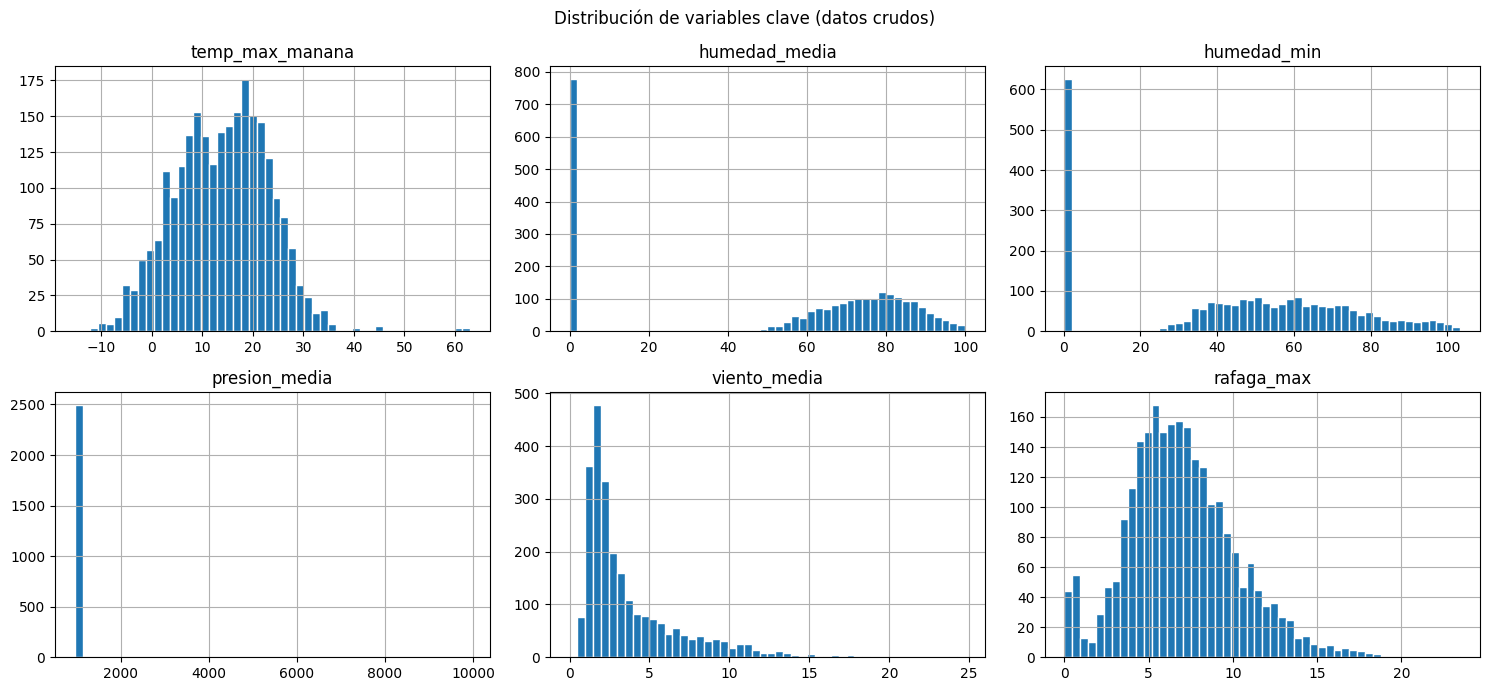

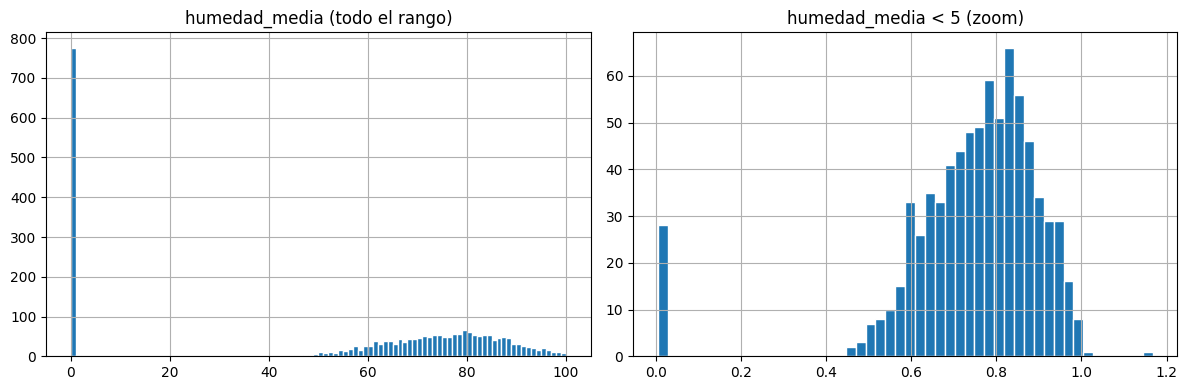

In [5]:
cols_hist = ['temp_max_manana', 'humedad_media', 'humedad_min', 'presion_media', 'viento_media', 'rafaga_max']

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), cols_hist):
    data[col].dropna().hist(bins=50, ax=ax, edgecolor='white')
    ax.set_title(col)
fig.suptitle('Distribución de variables clave (datos crudos)')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data['humedad_media'].dropna().hist(bins=100, ax=axes[0], edgecolor='white')
axes[0].set_title('humedad_media (todo el rango)')
data.loc[data['humedad_media'] < 5, 'humedad_media'].dropna().hist(bins=50, ax=axes[1], edgecolor='white')
axes[1].set_title('humedad_media < 5 (zoom)')
plt.tight_layout()
plt.show()

### 2.1.2 Descripción de los resultados de la exploración

De las estadísticas descriptivas y los histogramas anteriores se destacan los siguientes hallazgos, que son aplcados para el siguiente punto de limpieza:

- temp_max_manana: distribución normal, centrada alrededor de 13–14 °C, pero con valores extremos físicamente imposibles (+50c) a limpiar

- Humedad con dos escalas mezcladas: el histograma de humedad_media tiene 2 escalas en una, con un grupo grande entre 30 y 100 que es porcentaje, y otro grupo pegado en un rango de 0 a 1, que es fracción. Problema a corregir

- valores de error en las variables de viento y ráfaga aparecen valores de −9999, error claro de estos sensores a arreglar.

- Errores de escala en presión: existen valores de presion_media cercanos a 10000 hPa, lo cual desde la logica de negocio, y viendo el valor esperado es 10 veces mayor


- Inconsistencias estructurales: A su vez hay filas con erroes de minimo mayor que el maximo y ciertas incosisntecias en la digitacion de lenguajes y rotografia para las variables categoricas.

## 2.2 Clasificación de variables por tipo

Se separan y clasifican las variables del dataset según su tipo estadistico: cuantitativas continuas, cuantitativas discretas, cualitativas nominales y cualitativas ordinales.

In [6]:
cuantitativas_continuas = [
    'presion_media', 'presion_min', 'presion_max', 'presion_desv',
    'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
    'viento_media', 'viento_min', 'viento_max', 'viento_desv',
    'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
    'viento_norte', 'viento_este', 'direccion_viento',
    'temp_max_manana'
]
cuantitativas_discretas = ['registros_del_dia', 'anio', 'dia_del_anio']
cualitativas_nominales = ['fecha', 'estacion_anio', 'mes', 'sector_viento']
cualitativas_ordinales = []  

total_clasificadas = (len(cuantitativas_continuas)+ len(cuantitativas_discretas)+ len(cualitativas_nominales))

print("Total columnas clasificadas:", total_clasificadas)
print("Total columnas en el dataset:", data.shape[1])

Total columnas clasificadas: 27
Total columnas en el dataset: 27


# 3. Preprocesamiento y limpieza de datos

## 3.1 Análisis de valores nulos

Se revisa la cantidad y el porcentaje de valores nulos por columna, revisando aparte la variable objetivo

In [7]:
pct_nulos = (data.isnull().sum() / len(data) * 100).sort_values(ascending=False)
print("Porcentaje de valores nulos por columna:")
print(pct_nulos.round(2))

Porcentaje de valores nulos por columna:
temp_max_manana      3.69
viento_min           3.53
estacion_anio        3.42
mes                  3.42
anio                 3.34
humedad_max          3.34
viento_media         3.34
viento_max           3.14
humedad_min          3.11
viento_norte         3.11
presion_desv         3.11
rafaga_desv          3.07
direccion_viento     3.07
rafaga_media         3.03
registros_del_dia    2.99
presion_media        2.91
presion_min          2.87
humedad_media        2.87
rafaga_max           2.83
rafaga_min           2.80
viento_desv          2.80
fecha                2.80
sector_viento        2.76
dia_del_anio         2.64
presion_max          2.48
viento_este          2.48
humedad_desv         2.37
dtype: float64


In [8]:
nulos_target = data[data['temp_max_manana'].isna()]
print("Valores nulos en temp_max_manana:")
print(f"{len(nulos_target)} filas ({len(nulos_target) / len(data) * 100:.2f}%)")

filas_completas = data.dropna().shape[0]
print("\nFilas sin valores nulos:")
print(f"{filas_completas} de {len(data)} ({filas_completas / len(data) * 100:.2f}%)")

Valores nulos en temp_max_manana:
95 filas (3.69%)

Filas sin valores nulos:
1122 de 2576 (43.56%)


## 3.2 Revisión de duplicados y categorías

Se verifica si existen filas duplicadas y se revisan las categorías presentes en las principales variables cualitativas.

In [9]:
duplicados = data.duplicated().sum()
print("Filas duplicadas:", duplicados)

for col in ['estacion_anio', 'mes', 'sector_viento']:
    print(f"\nValores en la variable {col}:")
    print(data[col].value_counts())

Filas duplicadas: 4

Valores en la variable estacion_anio:
estacion_anio
primavera               517
invierno                511
otono                   500
verano                  487
Inverano                 71
Estacion_Desconocida     63
VERANO_INVIERNO          60
East                     48
VERANO                   19
autumn                   18
primaveraa               17
berano                   17
fall                     15
winter                   15
verno                    14
Otoño                    12
otoño                    11
invernio                 11
Primavera                10
PRIMAVERA                10
invierno                  9
INVIERNO                  9
Verano                    9
Invierno                  9
OTONO                     8
primav                    6
spring                    6
summer                    6
Name: count, dtype: int64

Valores en la variable mes:
mes
May           127
August        125
July          123
January       120
March       

Se observa que el dataset contiene valores en distintos idiomas, con espacios y escritos de forma diferente, lo que hace que valores que son lo mismo se cuenten como diferentes. Por ello es necesario realizar una limpieza de las variables categóricas.

## 3.3 Limpieza de variables categóricas

### 3.3.1 Limpieza de la variable "Estación del año"

#### 3.3.1.1 Investigación del valor "East"

Antes de aplicar la limpieza se revisan las filas donde `estacion_anio` vale `East`. "East" es una dirección, no una estación: es un error de registro. Las filas con este valor ocurren en meses de todas las estaciones y su dirección de viento real casi nunca es el este, así que no se puede recuperar la estación desde la propia fila.

**Decisión:** se trata como valor no reconocido: el diccionario de la sección siguiente lo convierte en `NaN` y más adelante el pipeline lo imputa con la moda. No se recupera la estación desde la fecha porque la estacionalidad ya entra al modelo por `mes_sin`/`mes_cos` y `dia_del_anio`.

In [10]:
# Espacios ocultos en las categorías
valores = data['estacion_anio'].dropna().unique()
for valor in valores:
    if valor.strip() != valor:
        print(f"Se encontraron espacios en: '{valor}'")

# Filas con el valor 'East': ¿cuántas son y qué contienen?
east = data[data['estacion_anio'].astype(str).str.strip().str.lower() == 'east']
print(f"\nFilas con 'East' en estacion_anio: {len(east)}")
display(east[['fecha', 'mes', 'estacion_anio', 'sector_viento', 'direccion_viento']].head(10))

Se encontraron espacios en: 'invierno '
Se encontraron espacios en: 'otoño '

Filas con 'East' en estacion_anio: 48


,fecha,mes,estacion_anio,sector_viento,direccion_viento
4,2009-01-05,January,East,N,6.2418
13,2009-01-14,January,East,S,176.4107
20,2009-01-21,January,East,S,181.3462
89,2009-03-31,March,East,NE,54.4351
97,2009-04-08,April,East,Suroeste,NaN
148,2009-05-29,May,East,N,355.9874
152,2009-06-02,NaN,East,O,279.1896
218,2009-08-07,August,East,NE,54.0571
248,2009-09-06,Sept,East,SO,224.7997
320,2009-11-17,November,East,SO,217.5956


#### 3.3.1.2 Normalización con diccionario de estaciones

Se normalizan las variables categóricas y se unifica el formato:

1. Se eliminan espacios y se pasa todo a minúsculas.
2. Se define un diccionario para unificar las estaciones en español, corregir errores tipográficos y las equivalencias en inglés.
3. Se aplica el diccionario para estandarizar las categorías; los valores no reconocidos se convierten en NaN.

In [11]:
data['estacion_anio'] = data['estacion_anio'].str.strip().str.lower()

mapeo_estacion = {
    'primavera': 'primavera', 'primaveraa': 'primavera', 'primav': 'primavera', 'spring': 'primavera',
    'verano': 'verano', 'berano': 'verano', 'summer': 'verano',
    'otono': 'otono', 'otoño': 'otono', 'autumn': 'otono', 'fall': 'otono',
    'invierno': 'invierno', 'invernio': 'invierno', 'verno': 'invierno', 'winter': 'invierno'
}

data['estacion_anio'] = data['estacion_anio'].map(mapeo_estacion)

print("Valores después de la limpieza:")
print(data['estacion_anio'].value_counts(dropna=False))

Valores después de la limpieza:
estacion_anio
invierno     578
primavera    566
otono        564
verano       538
NaN          330
Name: count, dtype: int64


In [12]:
valores_estacion = data['estacion_anio'].dropna().unique()
no_reconocidos = [valor for valor in valores_estacion if valor not in mapeo_estacion]

print("Valores no reconocidos:")
print(no_reconocidos)

Valores no reconocidos:
[]


### 3.3.2 Limpieza de la variable "Mes"

Se limpian y estandarizan los valores de la columna mes. Se consideran las diferentes formas de escribir los meses (español e inglés) y se convierten a su número correspondiente del 1 al 12. Finalmente se revisa la cantidad de registros por mes y se comprueba si quedaron valores sin identificar.


In [13]:
meses = {
    'january': 1, 'jan': 1, 'enero': 1, 'ene': 1,
    'february': 2, 'feb': 2, 'febrero': 2,
    'march': 3, 'mar': 3, 'marzo': 3,
    'april': 4, 'apr': 4, 'abril': 4,
    'may': 5, 'mayo': 5,
    'june': 6, 'jun': 6, 'junio': 6,
    'july': 7, 'jul': 7, 'julio': 7,
    'august': 8, 'aug': 8, 'agosto': 8, 'ago': 8,
    'september': 9, 'sep': 9, 'sept': 9, 'septiembre': 9,
    'october': 10, 'oct': 10, 'octubre': 10,
    'november': 11, 'nov': 11, 'noviembre': 11,
    'december': 12, 'dec': 12, 'diciembre': 12, 'dic': 12
}


data['mes'] = datos_clima['mes'].copy()
data['mes'] = data['mes'].astype(str).str.strip().str.lower()
data['mes'] = data['mes'].map(meses)

print("Cantidad de registros por mes:")
print(data['mes'].value_counts(dropna=False).sort_index())
print("\nCantidad de valores nulos:", data['mes'].isna().sum())

Cantidad de registros por mes:
mes
1.0     231
2.0     197
3.0     213
4.0     181
5.0     198
6.0     192
7.0     209
8.0     209
9.0     235
10.0    198
11.0    211
12.0    214
NaN      88
Name: count, dtype: int64

Cantidad de valores nulos: 88


In [14]:
# Investigar las filas donde el mes es nulo para decidir si se pueden recuperar
display(data[data['mes'].isna()].head())

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,viento_min,viento_max,viento_desv,rafaga_media,rafaga_min,rafaga_max,rafaga_desv,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
9,2009-01-10,1002.9676,1002.08,1003.99,0.6683,82.34080,59.670000,93.0,10.8955,0.6665,NaN,2.140000,0.3778,1.3066,0.380000,3.880000,0.5674,-0.5302,0.0725,172.2080,144.0,2009.0,10.0,NaN,NaN,S,-0.13
133,2009-05-14,985.7269,NaN,989.63,1.8369,59.11720,82.567768,38.2,12.9390,2.1539,0.04,3.224915,1.2907,3.7725,0.250000,5.436996,2.2962,-0.0783,1.3632,93.2880,144.0,2009.0,134.0,primavera,NaN,E,19.71
139,2009-05-20,993.5894,991.11,995.46,NaN,0.68171,0.488000,90.6,14.1982,1.6058,0.22,2.423347,0.9390,2.9010,9.245488,0.466028,1.4770,0.5880,0.4501,37.4298,144.0,2009.0,140.0,primavera,NaN,NE,24.20
152,2009-06-02,988.4847,986.08,991.06,1.6575,63.81240,38.700000,97.5,19.5476,1.8653,0.00,2.597331,1.0622,3.6069,9.728808,0.000000,1.8038,0.1919,-1.1860,279.1896,144.0,2009.0,153.0,NaN,NaN,O,13.73
164,2009-06-14,992.0323,989.38,994.62,2.0036,60.12090,37.360000,84.4,14.5664,1.5055,0.04,3.305694,0.9258,2.7099,NaN,6.880000,1.5850,-0.3908,-0.3494,221.7977,144.0,2009.0,165.0,verano,NaN,SO,21.84


In [15]:
# Recuperar el mes desde la columna 'fecha' donde sea posible
data['fecha'] = pd.to_datetime(data['fecha'], errors='coerce')
data.loc[data['mes'].isna(), 'mes'] = data['fecha'].dt.month

print(f"Valores nulos en 'mes' ahora: {data['mes'].isna().sum()}")

Valores nulos en 'mes' ahora: 1

### 3.3.3 Limpieza de la variable "Sector Viento"

Se estandarizan los valores de sector_viento, ya que una misma dirección puede aparecer escrita de distintas formas (por ejemplo, `Norte`, `north` o `n`). Se agrupan las variantes de cada sector en un diccionario, se eliminan espacios, se pasan a minúsculas y se reemplazan.

In [16]:
sector_variantes = {
    'N': ['n', 'norte', 'north'],
    'NE': ['ne', 'noreste', 'northeast'],
    'E': ['e', 'este', 'east'],
    'SE': ['se', 'sureste', 'southeast'],
    'S': ['s', 'sur', 'south'],
    'SO': ['so', 'suroeste', 'southwest'],
    'O': ['o', 'oeste', 'west'],
    'NO': ['no', 'noroeste', 'northwest']
}

mapeo_sector = {}
for codigo in sector_variantes:
    for variante in sector_variantes[codigo]:
        mapeo_sector[variante] = codigo

data['sector_viento'] = data['sector_viento'].str.strip()
data['sector_viento'] = data['sector_viento'].str.lower()
data['sector_viento'] = data['sector_viento'].map(mapeo_sector)

print("Variable sector_viento luego de la limpieza:")
print(data['sector_viento'].value_counts(dropna=False))

Variable sector_viento luego de la limpieza:
sector_viento
SO     774
S      582
NE     472
O      329
N      137
E       87
SE      72
NaN     71
NO      52
Name: count, dtype: int64


## 3.4 Eliminación de duplicados exactos

Se eliminan los registros completamente duplicados, conservando la primera aparición de cada uno.

In [17]:
print("Filas antes de eliminar duplicados:", len(data))
data = data.drop_duplicates()
print("Filas después de eliminar duplicados:", len(data))

Filas antes de eliminar duplicados: 2576
Filas después de eliminar duplicados: 2572


## 3.5 Validación de rangos y consistencia numérica

A continuación se verifican los rangos lógicos y físicos de las variables numéricas, así como la consistencia entre las variables de mínimo y máximo.

### 3.5.1 Revisar que los valores de humedad estén entre 0 y 100

In [18]:
print("Valores de humedad fuera de rango:")
columnas_humedad = ['humedad_media', 'humedad_min', 'humedad_max']

for col in columnas_humedad:
    datos_fuera = data[(data[col] < 0) | (data[col] > 100)]
    print(col, ":", len(datos_fuera), "registros fuera de rango")

Valores de humedad fuera de rango:
humedad_media : 0 registros fuera de rango
humedad_min : 23 registros fuera de rango
humedad_max : 0 registros fuera de rango


#### 3.5.1.1 Detección de escalas mezcladas (fracción 0–1 vs. porcentaje 0–100)

Posterior a eliminar valores fuera de rango, hay que arreglar el problema de que hay registros en porcentaje y otros en fracción. Un valor de humedad media o mínima menor a 1.5 **%** es físicamente implausible en este dataset (el mínimo "real" observado es ≈ 13 %), por lo que todo valor entre 0 y 1.5 se interpreta como una fracción 0–1 sin reescalar.

In [19]:
print("Celdas con valores en fracción (0 < valor < 1.5):")
for col in ['humedad_media', 'humedad_min', 'humedad_max']:
    mask = (data[col] > 0) & (data[col] < 1.5)
    print(f"  {col}: {mask.sum()} registros")

en_fraccion_media = (data['humedad_media'] > 0) & (data['humedad_media'] < 1.5)
en_fraccion_min = (data['humedad_min'] > 0) & (data['humedad_min'] < 1.5)
en_fraccion_max = (data['humedad_max'] > 0) & (data['humedad_max'] < 1.5)

print("\nFilas con la media en fracción pero el máximo en escala normal:",
      (en_fraccion_media & ~en_fraccion_max).sum())
print("Filas con el mínimo en fracción pero la media en escala normal:",
      (en_fraccion_min & ~en_fraccion_media).sum())
print("Humedad mínima legítima más baja (excluyendo fracciones):",
      data.loc[data['humedad_min'] >= 1.5, 'humedad_min'].min())

Celdas con valores en fracción (0 < valor < 1.5):
  humedad_media: 777 registros
  humedad_min: 625 registros
  humedad_max: 0 registros

Filas con la media en fracción pero el máximo en escala normal: 777
Filas con el mínimo en fracción pero la media en escala normal: 15
Humedad mínima legítima más baja (excluyendo fracciones): 12.95


**Resultado:** 777 celdas de humedad_media y 625 de humedad_min están registradas como fracción, mientras que humedad_max no presenta el problema. 

### 3.5.2 Revisar la dirección del viento (0-360)

In [20]:
datos_fuera = data[(data['direccion_viento'] < 0) | (data['direccion_viento'] > 360)]
print("Valores de direccion_viento fuera de rango:", len(datos_fuera), "registros")

Valores de direccion_viento fuera de rango: 0 registros


### 3.5.3 Revisar el día del año (1-366)

In [21]:
datos_fuera = data[(data['dia_del_anio'] < 1) | (data['dia_del_anio'] > 366)]
print("Valores de dia_del_anio fuera de rango:", len(datos_fuera), "registros")

Valores de dia_del_anio fuera de rango: 0 registros


### 3.5.4 Revisar la cantidad de registros del día (0-144)

In [22]:
datos_fuera = data[(data['registros_del_dia'] < 0) | (data['registros_del_dia'] > 144)]
print("Valores de registros_del_dia fuera de rango:", len(datos_fuera), "registros")

Valores de registros_del_dia fuera de rango: 4 registros


### 3.5.5 Consistencia entre valores mínimos y máximos

Se verifica que el valor mínimo no sea mayor que el máximo en cada par de variables relacionadas.

In [23]:
pares = [
    ('presion_min', 'presion_max'),
    ('humedad_min', 'humedad_max'),
    ('viento_min', 'viento_max'),
    ('rafaga_min', 'rafaga_max')
]

print("Inconsistencias entre mínimo y máximo:")
for minimo, maximo in pares:
    datos_incorrectos = data[data[minimo] > data[maximo]]
    print(minimo, ">", maximo, ":", len(datos_incorrectos), "registros")

Inconsistencias entre mínimo y máximo:


presion_min > presion_max : 121 registros
humedad_min > humedad_max : 98 registros
viento_min > viento_max : 120 registros
rafaga_min > rafaga_max : 122 registros


#### 3.5.5.1 Revisar valores de humedad mínima fuera de rango

Se identifican los registros donde humedad_min está fuera del rango 0-100 y se comparan con la media y el máximo.

In [24]:
fuera_humedad_min = data[(data['humedad_min'] < 0) | (data['humedad_min'] > 100)]
display(fuera_humedad_min[['humedad_min', 'humedad_media', 'humedad_max']])

,humedad_min,humedad_media,humedad_max
15,102.543211,92.75970,81.50
34,101.340609,91.93820,71.70
292,101.011049,84.45660,NaN
591,100.419571,93.59790,81.30
616,102.804131,0.86404,67.67
653,103.311405,96.85690,90.50
815,100.764528,75.42830,46.11
947,101.118476,71.25710,48.15
1004,101.324629,70.90570,39.84
1020,101.010117,80.39160,51.23


#### 3.5.5.2 Revisar valores de registros_del_dia fuera de rango

Se muestran la fecha y la cantidad de registros de los casos con valores fuera del rango esperado.

In [25]:
fuera_registros = data[(data['registros_del_dia'] < 0) | (data['registros_del_dia'] > 144)]
display(fuera_registros[['fecha', 'registros_del_dia']])

,fecha,registros_del_dia
546,2010-07-01,287.0
547,2010-07-02,145.0
1904,2014-03-20,222.0
1905,2014-03-21,249.0


#### 3.5.5.3 Revisar la presión mínima > máxima

Se revisan los registros donde la presión mínima es mayor que la máxima y se comprueba si el problema podría ser que los valores estan invertidos.

In [26]:
ejemplo_presion = data[data['presion_min'] > data['presion_max']]
display(ejemplo_presion[['presion_min', 'presion_media', 'presion_max', 'presion_desv']].head(10))

,presion_min,presion_media,presion_max,presion_desv
43,994.906458,989.2739,988.44,NaN
44,1003.735938,994.9869,989.00,3.6486
56,997.729414,990.5860,985.86,2.8527
70,998.971077,992.2961,987.30,3.0289
73,1003.906077,994.9090,989.35,3.4922
173,1001.645188,995.4420,993.44,1.0402
175,991.708627,986.9349,985.68,0.8907
178,995.017593,989.7090,989.08,NaN
211,1002.983578,996.3662,994.50,1.1829
212,999.423390,988.9680,984.72,3.3180


In [27]:
chequeo = ejemplo_presion.copy()
chequeo['seria_valido_si_se_invierte'] = (
    (chequeo['presion_max'] <= chequeo['presion_media']) &
    (chequeo['presion_media'] <= chequeo['presion_min'])
)
print(chequeo['seria_valido_si_se_invierte'].value_counts())

seria_valido_si_se_invierte
True     117
False      4
Name: count, dtype: int64


#### 3.5.5.4 Comprobar valores invertidos en viento, ráfagas y humedad

Para los registros donde el mínimo es mayor que el máximo, se comprueba si los valores podrían estar invertidos utilizando también la media. Esto estima cuántos casos podrían corregirse simplemente intercambiando mínimo y máximo.

In [28]:
variables = [
    ('viento_min', 'viento_max', 'viento_media'),
    ('rafaga_min', 'rafaga_max', 'rafaga_media'),
    ('humedad_min', 'humedad_max', 'humedad_media')
]

for col_min, col_max, col_media in variables:
    casos = data[data[col_min] > data[col_max]].copy()
    casos_validos = (
        (casos[col_max] <= casos[col_media]) &
        (casos[col_media] <= casos[col_min])
    )
    print(
        col_min, "vs", col_max, ":",
        casos_validos.sum(), "de", len(casos),
        "podrían corregirse invirtiendo los valores"
    )

viento_min

 vs viento_max : 115 de 120 podrían corregirse invirtiendo los valores


rafaga_min vs rafaga_max : 119 de 122 podrían corregirse invirtiendo los valores
humedad_min vs humedad_max : 90 de 98 podrían corregirse invirtiendo los valores


### 3.5.6 Revisión de fechas sospechosas

Se convierten las fechas al formato adecuado y se revisan algunas fechas previamente identificadas como sospechosas para observar si presentan valores atípicos en las demás variables.

In [29]:
fechas_sospechosas = ['2010-07-01', '2010-07-02', '2014-03-20', '2014-03-21']

data['fecha'] = pd.to_datetime(data['fecha'], errors='coerce')
sospechosos = data[data['fecha'].isin(pd.to_datetime(fechas_sospechosas))]

display(sospechosos)

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,viento_min,viento_max,viento_desv,rafaga_media,rafaga_min,rafaga_max,rafaga_desv,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
546,2010-07-01,990.4292,989.100000,992.06,0.8498,0.603077,37.5100,89.4,17.2378,1.4374,0.15,3.230000,0.8110,2.4914,0.36,5.32,1.2954,0.6590,0.2537,21.0579,287.0,2010.0,182.0,verano,8.0,N,30.61
547,2010-07-02,990.1361,988.920000,990.84,0.6349,0.546587,0.3367,85.4,17.2655,1.8548,0.16,3.784149,1.5966,3.0945,0.44,8.44,2.3459,0.3600,1.1351,72.4017,145.0,2010.0,183.0,NaN,7.0,E,31.30
1904,2014-03-20,990.3983,997.040631,984.78,3.6080,0.004663,NaN,83.1,17.4491,3.6486,0.66,6.120000,1.2352,5.4782,1.56,9.69,1.6437,-3.4513,-0.2815,184.6636,222.0,2014.0,79.0,NaN,11.0,S,19.92
1905,2014-03-21,982.6692,979.960000,984.97,1.5063,47.902900,36.1600,78.3,9.2391,4.9416,0.70,12.210000,3.4911,7.7055,1.46,18.13,5.2174,-4.1114,-2.3344,209.5877,249.0,2014.0,80.0,NaN,3.0,SO,11.57


## 3.6 Correcciones aplicadas

A partir de la validación anterior se aplican las correcciones necesarias a los datos.

### 3.6.1 Corregir registros_del_dia fuera de rango

Los valores de registros_del_dia que están fuera del rango esperado (0-144) se reemplazan por nulos para que no afecten los análisis posteriores.

In [30]:
fuera_de_rango = (data['registros_del_dia'] < 0) | (data['registros_del_dia'] > 144)
data.loc[fuera_de_rango, 'registros_del_dia'] = np.nan

### 3.6.2 Corrección de escalas mezcladas en la humedad

Según lo detectado, los valores de humedad_media y humedad_min entre 0 y 1.5 corresponden a registros almacenados como fracción. Se reescalan multiplicando por 100 para unificar todo en porcentaje

In [31]:
for col in ['humedad_media', 'humedad_min']:
    mask = (data[col] > 0) & (data[col] < 1.5)
    data.loc[mask, col] = data.loc[mask, col] * 100
    print(f"{col}: {mask.sum()} valores en fracción reescalados a porcentaje (x100)")

humedad_media: 777 valores en fracción reescalados a porcentaje (x100)
humedad_min: 625 valores en fracción reescalados a porcentaje (x100)


### 3.6.3 Corregir valores mínimo y máximo

Se corrigen los casos en los que una variable tiene el mínimo mayor que el máximo. Si los valores están simplemente invertidos (la media queda entre ambos al intercambiarlos), se intercambian; de lo contrario, se reemplazan por nulos. Para ello se define una función reutilizable.

In [32]:
def corregir_min_max(data, minimo, maximo, media):
    casos = data[minimo] > data[maximo]
    se_pueden_cambiar = (
        casos &
        (data[maximo] <= data[media]) &
        (data[media] <= data[minimo])
    )

    temporal = data.loc[se_pueden_cambiar, minimo].copy()
    data.loc[se_pueden_cambiar, minimo] = data.loc[se_pueden_cambiar, maximo]
    data.loc[se_pueden_cambiar, maximo] = temporal

    no_validos = casos & ~se_pueden_cambiar
    data.loc[no_validos, [minimo, maximo]] = None

    print(
        minimo, "/", maximo, ":",
        se_pueden_cambiar.sum(), "corregidos y",
        no_validos.sum(), "marcados como nulos"
    )
    return data

In [33]:
variables_correccion = [
    ('presion_min', 'presion_max', 'presion_media'),
    ('viento_min', 'viento_max', 'viento_media'),
    ('rafaga_min', 'rafaga_max', 'rafaga_media'),
    ('humedad_min', 'humedad_max', 'humedad_media')
]

for minimo, maximo, media in variables_correccion:
    data = corregir_min_max(data, minimo, maximo, media)

presion_min / presion_max : 117 corregidos y 4 marcados como nulos
viento_min / viento_max : 115 corregidos y 5 marcados como nulos
rafaga_min / rafaga_max : 119 corregidos y 3 marcados como nulos
humedad_min / humedad_max : 115 corregidos y 6 marcados como nulos


#### 3.6.3.1 Comprobar los resultados de la corrección mín/máx

Se verifica si después de las correcciones todavía quedan inconsistencias entre los valores mínimos y máximos, y se revisa nuevamente el rango de la humedad.

In [34]:
pares = [
    ('presion_min', 'presion_max'),
    ('viento_min', 'viento_max'),
    ('rafaga_min', 'rafaga_max'),
    ('humedad_min', 'humedad_max')
]

for minimo, maximo in pares:
    casos = (data[minimo] > data[maximo]).sum()
    print(minimo, ">", maximo, ":", casos, "casos restantes")

fuera_humedad_min = ((data['humedad_min'] < 0) | (data['humedad_min'] > 100)).sum()
fuera_humedad_max = ((data['humedad_max'] < 0) | (data['humedad_max'] > 100)).sum()

print("\nHumedad mínima fuera de rango:", fuera_humedad_min)
print("Humedad máxima fuera de rango:", fuera_humedad_max)

presion_min > presion_max : 0 casos restantes
viento_min > viento_max : 0 casos restantes
rafaga_min > rafaga_max : 0 casos restantes
humedad_min > humedad_max : 0 casos restantes

Humedad mínima fuera de rango: 1
Humedad máxima fuera de rango: 26


### 3.6.4 Ajustar la humedad al rango permitido (0-100)

Se recortan (`clip`) los valores de humedad mínima y máxima para asegurar que se encuentren entre 0 y 100, y se verifica que no queden valores fuera del rango.

In [35]:
data['humedad_min'] = data['humedad_min'].clip(0, 100)
data['humedad_max'] = data['humedad_max'].clip(0, 100)

fuera_min = ((data['humedad_min'] < 0) | (data['humedad_min'] > 100)).sum()
fuera_max = ((data['humedad_max'] < 0) | (data['humedad_max'] > 100)).sum()

print("humedad_min fuera de rango:", fuera_min)
print("humedad_max fuera de rango:", fuera_max)

humedad_min fuera de rango: 0
humedad_max fuera de rango: 0


### 3.6.5 Corregir valores negativos y centinela en viento y ráfagas

Las velocidades del viento y las ráfagas no pueden ser negativas. Además, algunos registros presentan el valor centinela -9999.0 para indicar datos inválidos o faltantes. En esta sección se centralizan y unifican todas estas correcciones:

1. Se reemplazan **todos** los valores -9999 del DataFrame por Nan.


In [36]:

data.replace(-9999.0, np.nan, inplace=True)
print("Valores -9999.0 reemplazados por NaN en todo el DataFrame.")

Valores -9999.0 reemplazados por NaN en todo el DataFrame.


In [37]:

columnas_velocidad_viento = [
    'viento_min', 'viento_media', 'viento_max',
    'rafaga_min', 'rafaga_media', 'rafaga_max', 'rafaga_desv'
]

print("Valores negativos corregidos a NaN en columnas de velocidad:")
for col in columnas_velocidad_viento:
    negativos_antes = (data[col] < 0).sum()
    if negativos_antes > 0:
        data.loc[data[col] < 0, col] = np.nan
        print(f"  - '{col}': {negativos_antes} valores negativos corregidos.")
    else:
        print(f"  - '{col}': No se encontraron valores negativos a corregir.")

Valores negativos corregidos a NaN en columnas de velocidad:
  - 'viento_min': No se encontraron valores negativos a corregir.
  - 'viento_media': No se encontraron valores negativos a corregir.
  - 'viento_max': No se encontraron valores negativos a corregir.
  - 'rafaga_min': No se encontraron valores negativos a corregir.
  - 'rafaga_media': 1 valores negativos corregidos.
  - 'rafaga_max': No se encontraron valores negativos a corregir.
  - 'rafaga_desv': 254 valores negativos corregidos.


### 3.6.6 Limpiar valores imposibles (outliers)

Se corrigen valores que son físicamente imposibles o que claramente están fuera del rango esperado para cada variable. Estos valores se consideran outliers y se reemplazan por NaN para evitar que distorsionen los análisis.

In [38]:

mask_escala = data['presion_media'] > 2000
print(f"presion_media: {mask_escala.sum()} valores corregidos por error de escala (÷10).")
data.loc[mask_escala, 'presion_media'] = data.loc[mask_escala, 'presion_media'] / 10

# Verificación
print("presion_media fuera de rango tras la corrección:", (data['presion_media'] > 2000).sum())
display(data.loc[[21, 662, 1462, 2561, 2562], ['presion_min', 'presion_media', 'presion_max']])

presion_media: 5 valores corregidos por error de escala (÷10).
presion_media fuera de rango tras la corrección: 0


,presion_min,presion_media,presion_max
21,971.48,978.4115,983.54
662,986.97,992.8772,998.17
1462,985.61,993.9918,1001.18
2561,985.61,993.9918,1001.18
2562,986.97,992.8772,998.17


In [39]:
limites_outliers = {
    'humedad_min': ('>', 100),
    'temp_max_manana': ('>', 50)
}

for col, (operador, limite) in limites_outliers.items():
    mask = data[col] > limite
    valores_fuera = mask.sum()
    if valores_fuera > 0:
        print(f"'{col}': valores encontrados antes de corregir:")
        print(data.loc[mask, col])
        data.loc[mask, col] = np.nan
        print(f"'{col}': {valores_fuera} valores > {limite} corregidos a NaN.\n")
    else:
        print(f"'{col}': No se encontraron valores > {limite} a corregir.")

'humedad_min': No se encontraron valores > 100 a corregir.
'temp_max_manana': valores encontrados antes de corregir:
1372    63.050
1570    61.412
2557    63.050
Name: temp_max_manana, dtype: float64
'temp_max_manana': 3 valores > 50 corregidos a NaN.



### 3.6.7 Eliminación de filas con objetivo nulo

Se eliminan las filas donde la variable objetivo temp_max_manana es nula, ya que no es posible utilizarlas para entrenar un modelo. Este paso se hace al final de las correcciones, después de anular los valores imposibles del objetivo.

In [40]:
print(f"Filas antes de eliminar target nulo: {data.shape[0]}")
data = data.dropna(subset=['temp_max_manana'])
print(f"Filas después: {data.shape[0]}")

Filas antes de eliminar target nulo: 2572


Filas después: 2474


## 3.7 Codificación de variables cíclicas (mes y dirección del viento)

Las variables `mes` (1-12) y `direccion_viento` (0-360°) son circulares: diciembre y enero son meses vecinos, y 359° y 0° son direcciones casi idénticas. Si se tratan como números lineales, el modelo interpretaría distancias falsas entre esos valores. Por eso se codifican con seno y coseno, que preservan la geometría del círculo.

In [41]:
# Codificación cíclica de 'mes' (periodo = 12)
data['mes_sin'] = np.sin(2 * np.pi * data['mes'] / 12)
data['mes_cos'] = np.cos(2 * np.pi * data['mes'] / 12)

# Codificación cíclica de 'direccion_viento' (periodo = 360)
data['direccion_viento_sin'] = np.sin(2 * np.pi * data['direccion_viento'] / 360)
data['direccion_viento_cos'] = np.cos(2 * np.pi * data['direccion_viento'] / 360)

# Verificación rápida: ver cómo quedaron algunos meses de ejemplo
display(data[['mes', 'mes_sin', 'mes_cos']].drop_duplicates(subset='mes').sort_values('mes'))

,mes,mes_sin,mes_cos
0,1.0,5.000000e-01,8.660254e-01
35,2.0,8.660254e-01,5.000000e-01
42,3.0,1.000000e+00,6.123234e-17
16,4.0,8.660254e-01,-5.000000e-01
7,5.0,5.000000e-01,-8.660254e-01
11,6.0,1.224647e-16,-1.000000e+00
1,7.0,-5.000000e-01,-8.660254e-01
34,8.0,-8.660254e-01,-5.000000e-01
14,9.0,-1.000000e+00,-1.836970e-16
21,10.0,-8.660254e-01,5.000000e-01


La codificación cíclica busca que valores "cercanos en el círculo" queden cercanos en el espacio de características. Para comprobarlo, a continuación se revisan direcciones de viento en los extremos del rango: 0° y 359° son físicamente casi la misma dirección y, con la codificación sin/cos, sus valores transformados resultan casi iguales (cos ≈ 1, sin ≈ 0 en ambos casos), mientras que 180° queda en el punto opuesto del círculo (cos ≈ −1). Esto confirma que la transformación preserva la cercanía real que la variable original en grados no captura.

In [42]:
# Buscar valores cercanos a 0°, 359° y 180° (con margen de tolerancia)
cerca_0 = data[(data['direccion_viento'] >= 0) & (data['direccion_viento'] <= 2)]
cerca_359 = data[(data['direccion_viento'] >= 357) & (data['direccion_viento'] <= 360)]
cerca_180 = data[(data['direccion_viento'] >= 179) & (data['direccion_viento'] <= 181)]

print("Cerca de 0°:")
display(cerca_0[['direccion_viento', 'direccion_viento_sin', 'direccion_viento_cos']].head(3))

print("Cerca de 359°:")
display(cerca_359[['direccion_viento', 'direccion_viento_sin', 'direccion_viento_cos']].head(3))

print("Cerca de 180°:")
display(cerca_180[['direccion_viento', 'direccion_viento_sin', 'direccion_viento_cos']].head(3))

Cerca de 0°:


,direccion_viento,direccion_viento_sin,direccion_viento_cos
27,0.0000,0.000000,1.000000
220,0.3941,0.006878,0.999976
1987,0.6308,0.011009,0.999939


Cerca de 359°:


,direccion_viento,direccion_viento_sin,direccion_viento_cos
112,358.0213,-0.034528,0.999404
812,357.7938,-0.038496,0.999259
1042,358.3763,-0.028335,0.999598


Cerca de 180°:


,direccion_viento,direccion_viento_sin,direccion_viento_cos
7,179.7388,0.004559,-0.999990
231,179.7356,0.004615,-0.999989
295,179.5755,0.007409,-0.999973


## 3.8 Función de limpieza reutilizable

Para aplicar exactamente la misma limpieza al archivo de test (y a cualquier dato futuro), todo el procedimiento anterior se encapsula en la función limpiar_datos_clima, que reproduce paso a paso las decisiones tomadas en las secciones 3.3 a 3.7.

In [43]:
def limpiar_datos_clima(df):
    """Aplica sobre un DataFrame crudo la misma limpieza que el notebook."""
    # Se trabaja sobre una copia para no modificar el DataFrame original
    df = df.copy()

    # Se normaliza la columna 'fecha' al tipo datetime. Se aceptan tanto el
    # formato ISO del train (2009-01-01) como el formato dd.mm.yyyy del
    # archivo de test (01.01.2016); las fechas invalidas quedan como NaT
    fecha_gen = pd.to_datetime(df["fecha"], errors="coerce")
    fecha_eu = pd.to_datetime(df["fecha"], format="%d.%m.%Y", errors="coerce")
    df["fecha"] = fecha_gen.fillna(fecha_eu)

    # 1. Normalizacion de variables categoricas
    # Elimina espacios al inicio/final y se pasan a minusculas para unificar las
    # diferentes escrituras. Los valores nulos se convierten a
    # NaN porque al transformarlos a string aparecerian como 'nan'
    for col in ["estacion_anio", "mes", "sector_viento"]:
        df[col] = df[col].astype(str).str.strip().str.lower()
        df.loc[df[col] == "nan", col] = np.nan

    # 1a. estacion_anio: Unifica ingles/espanol y corrige errores tipograficos
    # ('primaveraa', 'primav'). Los valores no reconocidos quedan como NaN
    mapeo_estacion = {
        "primavera": "primavera", "primaveraa": "primavera", "primav": "primavera", "spring": "primavera",
        "verano": "verano", "berano": "verano", "summer": "verano",
        "otono": "otono", "oto\u00f1o": "otono", "autumn": "otono", "fall": "otono",
        "invierno": "invierno", "invernio": "invierno", "verno": "invierno", "winter": "invierno",
    }
    df["estacion_anio"] = df["estacion_anio"].map(mapeo_estacion)

    # 1b. mes: diccionario con las variantes de los meses (ingles y espanol)
    # convertidas a su numero (1-12)
    meses = {
        "january": 1, "jan": 1, "enero": 1, "ene": 1,
        "february": 2, "feb": 2, "febrero": 2,
        "march": 3, "mar": 3, "marzo": 3,
        "april": 4, "apr": 4, "abril": 4,
        "may": 5, "mayo": 5,
        "june": 6, "jun": 6, "junio": 6,
        "july": 7, "jul": 7, "julio": 7,
        "august": 8, "aug": 8, "agosto": 8, "ago": 8,
        "september": 9, "sep": 9, "sept": 9, "septiembre": 9,
        "october": 10, "oct": 10, "octubre": 10,
        "november": 11, "nov": 11, "noviembre": 11,
        "december": 12, "dec": 12, "diciembre": 12, "dic": 12,
    }
    df["mes"] = df["mes"].map(meses)
    # Si un mes no fue reconocido, se intenta recuperar de la fecha; si la
    # fecha tampoco existe, queda como NaN
    df.loc[df["mes"].isna(), "mes"] = df["fecha"].dt.month

    # 1c. sector_viento: variantes de cada punto cardinal (espanol/ingles y
    # abreviaciones) agrupadas bajo el codigo de 1 o 2 letras
    sector_variantes = {
        "N": ["n", "norte", "north"],
        "NE": ["ne", "noreste", "northeast"],
        "E": ["e", "este", "east"],
        "SE": ["se", "sureste", "southeast"],
        "S": ["s", "sur", "south"],
        "SO": ["so", "suroeste", "southwest"],
        "O": ["o", "oeste", "west"],
        "NO": ["no", "noroeste", "northwest"],
    }
    mapeo_sector = {variante: codigo for codigo, variantes in sector_variantes.items() for variante in variantes}
    df["sector_viento"] = df["sector_viento"].map(mapeo_sector)

    # 1d. Correccion de escalas mezcladas en humedad: los valores de
    # humedad_media y humedad_min entre 0 y 1.5 estan registrados como
    # fraccion (0-1) y se reescalan a porcentaje (x100). Se hace ANTES de la
    # correccion min/max para que las columnas esten en la misma escala.
    # El umbral 1.5 es seguro: el minimo legitimo del dataset es ~13%.
    for col in ["humedad_media", "humedad_min"]:
        mask = (df[col] > 0) & (df[col] < 1.5)
        df.loc[mask, col] = df.loc[mask, col] * 100

    # 2. Corregir valores minimo > maximo
    # Cuando el minimo es mayor que el maximo, verifica si los valores estan
    # invertidos. En este caso se intercambian; sino ambos valores se consideran
    # invalidados y pasan a None
    def corregir_min_max(df, minimo, maximo, media):
        # Casos donde el minimo supera al maximo (Inconsistencia)
        casos = df[minimo] > df[maximo]
        # Solo se intercambian si la media queda contenida entre el maximo
        # original (que pasaria a ser el minimo) y el minimo original
        se_pueden_cambiar = casos & (df[maximo] <= df[media]) & (df[media] <= df[minimo])
        temporal = df.loc[se_pueden_cambiar, minimo].copy()
        df.loc[se_pueden_cambiar, minimo] = df.loc[se_pueden_cambiar, maximo]
        df.loc[se_pueden_cambiar, maximo] = temporal
        # Los casos que no se pueden corregir se dejan como nulos para que
        # no distorsionen los analisis posteriores
        no_validos = casos & ~se_pueden_cambiar
        df.loc[no_validos, [minimo, maximo]] = None
        return df

    # Se aplica el mismo procedimiento a las 4 variables con minimo/maximo,
    # conservando el mismo orden que la limpieza manual del notebook
    for minimo, maximo, media in [
        ("presion_min", "presion_max", "presion_media"),
        ("viento_min", "viento_max", "viento_media"),
        ("rafaga_min", "rafaga_max", "rafaga_media"),
        ("humedad_min", "humedad_max", "humedad_media"),
    ]:
        df = corregir_min_max(df, minimo, maximo, media)

    # 3. Ajustar humedad al rango fisico [0, 100]
    # Se recortan los valores extremos (Valores puntuales por arriba
    # de 100 tras el intercambio) para garantizar humedad_min <= humedad_max
    df["humedad_min"] = df["humedad_min"].clip(0, 100)
    df["humedad_max"] = df["humedad_max"].clip(0, 100)
    # Los registros del dia deben estar entre 0 y 144, los valores fuera de
    # rango se reemplazan por nulos
    df.loc[(df["registros_del_dia"] < 0) | (df["registros_del_dia"] > 144), "registros_del_dia"] = None

    # 4. Reemplazar el valor centinela -9999 por NaN
    # Los sensores usan -9999.0 para senalar datos faltantes o invalidos.
    # Se reemplaza en todo el DataFrame para que no se tome como dato real
    df.replace(-9999.0, np.nan, inplace=True)

    # 5. Corregir velocidades negativas a NaN
    # Una velocidad de viento o rafaga no puede ser negativa; los valores
    # menores a 0 se consideran errores de signo y se transforman en nulos.
    columnas_velocidad = [
        "viento_min", "viento_media", "viento_max",
        "rafaga_min", "rafaga_media", "rafaga_max", "rafaga_desv",
    ]
    for col in columnas_velocidad:
        df.loc[df[col] < 0, col] = np.nan

    # 6. Corregir la escala de presion_media
    # Algunos valores de presion estan en una escala erronea (por encima de
    # 2000 hPa, imposible para la presion atmosferica), asumimos que son
    # diez veces el valor real, por lo que se divide entre 10.
    mask_escala = df["presion_media"] > 2000
    df.loc[mask_escala, "presion_media"] = df.loc[mask_escala, "presion_media"] / 10

    # 7. Limpiar outliers fisicamente imposibles
    # humedad_min mayor a 100: Es un error de registro
    df.loc[df["humedad_min"] > 100, "humedad_min"] = np.nan

    # temp_max_manana mayor a 50 grados es imposible para la
    # temperatura maxima en la manana, por lo que se se anula ANTES del dropna
    # del target en el pipeline de entrenamiento
    if "temp_max_manana" in df.columns:
        df.loc[df["temp_max_manana"] > 50, "temp_max_manana"] = np.nan

    # 8. Variables ciclicas
    # Las variables ciclicas (mes del anio y direccion del viento) no deben
    # tratarse como numeros lineales (diciembre y enero estan cerca aunque
    # sean 12 y 1). Se codifican con sin/cos para preservar esa cercania.
    df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
    df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)
    df["direccion_viento_sin"] = np.sin(2 * np.pi * df["direccion_viento"] / 360)
    df["direccion_viento_cos"] = np.cos(2 * np.pi * df["direccion_viento"] / 360)
    return df

In [44]:
data_train = data.copy()

# Al conjunto de test se le aplica la misma función de limpieza
# (en Colab el archivo debe estar subido en el panel de archivos)
datos_test_crudo = pd.read_csv('Datos Test Lab 1.csv')
data_test = limpiar_datos_clima(datos_test_crudo)
print(f"Archivo de test cargado: {datos_test_crudo.shape[0]} filas")

Archivo de test cargado: 364 filas


## 3.9 Revisión final de la limpieza

Se realiza una revisión general del conjunto de datos después de aplicar todas las correcciones: dimensiones, porcentaje de valores nulos, filas duplicadas y categorías válidas. También se muestra el resumen estadístico final para validar que los rangos son físicamente posibles.

In [45]:
print("ESTADO FINAL DEL DATAFRAME DE TRAIN:")
print("Filas:", data_train.shape[0])
print("Columnas:", data_train.shape[1])

print("\nValores nulos por columna:")
nulos = (data_train.isnull().sum() / len(data_train) * 100).round(2)
print(nulos.sort_values(ascending=False))

print("\nDuplicados:")
print("Filas duplicadas:", data_train.duplicated().sum())

print("\nCategorías:")
for col in ['estacion_anio', 'mes', 'sector_viento']:
    print(col, ":", data_train[col].nunique(), "categorías válidas")

print("\n\nESTADO FINAL DEL DATAFRAME DE TEST:")
print("Filas:", data_test.shape[0])
print("Columnas:", data_test.shape[1])

print("\nValores nulos por columna:")
nulos = (data_test.isnull().sum() / len(data_test) * 100).round(2)
print(nulos.sort_values(ascending=False))

print("\nDuplicados:")
print("Filas duplicadas:", data_test.duplicated().sum())

print("\nCategorías:")
for col in ['estacion_anio', 'mes', 'sector_viento']:
    print(col, ":", data_test[col].nunique(), "categorías válidas")

ESTADO FINAL DEL DATAFRAME DE TRAIN:
Filas: 2474
Columnas: 31

Valores nulos por columna:
rafaga_desv             12.93
estacion_anio           12.69
viento_min               3.84
humedad_max              3.64
humedad_min              3.44
viento_media             3.40
viento_max               3.31
anio                     3.31
presion_desv             3.23
registros_del_dia        3.15
viento_norte             3.15
rafaga_max               3.07
rafaga_media             3.07
direccion_viento         3.03
direccion_viento_cos     3.03
direccion_viento_sin     3.03
presion_min              2.95
rafaga_min               2.95
humedad_media            2.91
presion_media            2.87
fecha                    2.83
viento_desv              2.75
sector_viento            2.71
presion_max              2.63
dia_del_anio             2.59
viento_este              2.43
humedad_desv             2.38
mes_cos                  0.04
mes                      0.04
mes_sin                  0.04
temp_max_m

## 3.10 Correlación con la variable objetivo

Con los datos ya limpios se calcula la correlación lineal de cada variable numérica con temp_max_manana

In [46]:
numericas = data_train.select_dtypes(include=[np.number]).columns.drop('temp_max_manana')
correlaciones = data_train[list(numericas) + ['temp_max_manana']].corr()['temp_max_manana'].drop('temp_max_manana')
correlaciones = correlaciones.reindex(correlaciones.abs().sort_values(ascending=False).index)

print("Correlación con temp_max_manana (ordenada por |r|):")
print(correlaciones.round(3))

Correlación con temp_max_manana (ordenada por |r|):
humedad_min            -0.583
humedad_desv            0.583
humedad_media          -0.431
mes_cos                -0.365
rafaga_min             -0.272
presion_desv           -0.209
mes_sin                -0.191
dia_del_anio            0.166
viento_min             -0.160
presion_min             0.146
humedad_max            -0.138
rafaga_media           -0.135
presion_media           0.115
anio                    0.093
mes                     0.086
viento_media           -0.071
presion_max             0.065
direccion_viento_sin    0.054
direccion_viento_cos   -0.043
rafaga_max              0.039
viento_desv             0.031
viento_norte           -0.022
rafaga_desv             0.022
direccion_viento        0.014
viento_max              0.013
viento_este             0.010
registros_del_dia      -0.007
Name: temp_max_manana, dtype: float64


Las correlaciones más fuertes con la temperatura máxima del día siguiente provienen de la humedad: humedad_min (r ≈ −0.58), humedad_desv (r ≈ +0.58) y humedad_media (r ≈ −0.43). Ninguna variable individual supera r = 0.6, lo que anticipa que la predicción requiere combinar muchas variables y que un modelo lineal difícilmente alcanzará un ajuste muy alto.


# 4. Modelado y Entrenamiento

## 4.1 Definición de Estrategias de Preprocesamiento

### 4.1.1 Estrategia A 

#### Descripción:
- Variables numéricas continuas: Se hace imputación de nulos con la mediana, y (StandardScaler).
- mes y direccion_viento: no se usan directamente, en su lugar entran sus versiones cíclicas (mes_sin, mes_cos, direccion_viento_sin, direccion_viento_cos), tratadas como numéricas dentro del pipeline
- Variables categóricas: imputación con la moda (SimpleImputer(strategy=most_frequent)) + OneHotEncoder.

#### Justificación:
La mediana es más robusta que la media ante valores atípicos. 

La codificación cíclica representa de forma matemáticamente correcta la naturaleza circular de mes y direccion_viento, evitando que el modelo interprete distancias falsas. Esto debería traducirse en coeficientes más interpretables y, potencialmente, mejor ajuste si la estacionalidad o la dirección del viento tienen relación real con la temperatura máxima del día siguiente.


### 4.1.2 Estrategia B 

#### Descripción:
- Variables numéricas continuas: imputación de nulos con la media, seguida de escalado (StandardScaler).
- mes y direccion_viento: se usan tal cual, como variables numéricas simples (sin transformación cíclica), dentro del mismo grupo de imputación con media + escalado.
- Variables categóricas: igual que en la Estrategia A

#### Justificación:
La media es la estrategia de imputación más común y sencilla. Tratar mes y direccion_viento como números simples es el enfoque "ingenuo" pero válido como línea base, que ignora la naturaleza cíclica de esas variables.


Para que la comparación sea justa, ambas estrategias se entrenan y evalúan con el mismo conjunto de datos y el mismo split; las únicas diferencias reales son las dos decisiones bajo estudio (cíclico vs. no cíclico, mediana vs. media), de modo que cualquier diferencia en las métricas pueda atribuirse a la estrategia de preparación y no a otro factor no controlado.

## 4.2 Implementación de Pipelines y Entrenamiento Inicial

In [47]:
# Variable objetivo
target = 'temp_max_manana'


cat_cols = ['estacion_anio', 'sector_viento']


num_cols_base = [
    'presion_media', 'presion_min', 'presion_max', 'presion_desv',
    'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
    'viento_media', 'viento_min', 'viento_max', 'viento_desv',
    'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
    'viento_norte', 'viento_este',
    'registros_del_dia', 'anio', 'dia_del_anio'
]

# Estrategia A: cíclicas
num_cols_A = num_cols_base + ['mes_sin', 'mes_cos', 'direccion_viento_sin', 'direccion_viento_cos']

# Estrategia B: numéricas simples
num_cols_B = num_cols_base + ['mes', 'direccion_viento']

print("Cantidad de numéricas en A:", len(num_cols_A))
print("Cantidad de numéricas en B:", len(num_cols_B))

Cantidad de numéricas en A: 25
Cantidad de numéricas en B: 23


### 4.2.1 Construcción del ColumnTransformer

In [48]:
# Estrategia A
num_transformer_A = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor_A = ColumnTransformer(transformers=[
    ('num', num_transformer_A, num_cols_A),
    ('cat', cat_transformer, cat_cols)
])

 # Estrategia B
num_transformer_B = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor_B = ColumnTransformer(transformers=[
    ('num', num_transformer_B, num_cols_B),
    ('cat', cat_transformer, cat_cols)  # el mismo transformador categórico, reutilizado
])

### 4.2.2 Integración del Modelo en el Pipeline

In [49]:
pipeline_A = Pipeline(steps=[
    ('preprocessor', preprocessor_A),
    ('model', LinearRegression())
])

pipeline_B = Pipeline(steps=[
    ('preprocessor', preprocessor_B),
    ('model', LinearRegression())
])

### 4.2.3 Preparación de Conjuntos de Entrenamiento y Validación

In [50]:

todas_las_predictoras = list(set(num_cols_A + num_cols_B + cat_cols))

X_train = data_train[todas_las_predictoras]
y_train = data_train['temp_max_manana']

X_test = data_test[todas_las_predictoras]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)

# Verificación no nulos en y
print("\nNulos en y_train:", y_train.isna().sum())

X_train shape: (2474, 29)
y_train shape: (2474,)
X_test shape: (364, 29)

Nulos en y_train: 0


### 4.2.4 Entrenamiento inicial

Se entrenan ambos pipelines con la totalidad de los datos de entrenamiento, como verificación de que el flujo completo.

In [51]:
pipeline_A.fit(X_train, y_train)
pipeline_B.fit(X_train, y_train)

print("Pipeline A entrenado.")
print("Pipeline B entrenado.")

Pipeline A entrenado.
Pipeline B entrenado.


# 5. Evaluación y Validación de Supuestos

In [52]:
from sklearn.model_selection import train_test_split

# Split (usando los X_train/y_train completos que ya construiste)
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

print("X_train_split:", X_train_split.shape)
print("X_val_split:", X_val_split.shape)

# Reentrenar ambos pipelines, esta vez SOLO con la porción de entrenamiento
pipeline_A.fit(X_train_split, y_train_split)
pipeline_B.fit(X_train_split, y_train_split)

print("\nPipeline A reentrenado con la porción de train_split.")
print("Pipeline B reentrenado con la porción de train_split.")

X_train_split: (1855, 29)
X_val_split: (619, 29)



Pipeline A reentrenado con la porción de train_split.
Pipeline B reentrenado con la porción de train_split.


## 5.1 Comparación de Estrategias

## Predicciones de cada pipeline sobre el conjunto de validación

In [53]:
y_pred_A = pipeline_A.predict(X_val_split)
y_pred_B = pipeline_B.predict(X_val_split)

## Métricas - Estrategia A

In [54]:
rmse_A = np.sqrt(mean_squared_error(y_val_split, y_pred_A))
mae_A = mean_absolute_error(y_val_split, y_pred_A)
r2_A = r2_score(y_val_split, y_pred_A)

## Métricas - Estrategia B

In [55]:
rmse_B = np.sqrt(mean_squared_error(y_val_split, y_pred_B))
mae_B = mean_absolute_error(y_val_split, y_pred_B)
r2_B = r2_score(y_val_split, y_pred_B)

### 5.1.1 Tabla Comparativa de Métricas

In [56]:
tabla_comparativa = pd.DataFrame({
    'Estrategia': ['A (cíclica + mediana)', 'B (numérica simple + media)'],
    'RMSE': [rmse_A, rmse_B],
    'MAE': [mae_A, mae_B],
    'R2': [r2_A, r2_B]
})

display(tabla_comparativa)

,Estrategia,RMSE,MAE,R2
0,A (cíclica + mediana),6.274498,4.886651,0.518634
1,B (numérica simple + media),6.489920,5.080423,0.485013


### 5.1.2 Interpretación de Resultados iniciales

La Estrategia A obtuvo mejor desempeño que la Estrategia B en las tres métricas: menor RMSE (6.27 °C vs. 6.49 °C), menor MAE (4.89 °C vs. 5.08 °C) y mayor R² (0.519 vs. 0.485). Esto sugiere que representar correctamente la naturaleza circular del tiempo y de la dirección del viento, junto con una imputación más robusta a valores atípicos, aporta una mejora real y consistente sobre un enfoque más simple.

Sin embargo, un R² de ~0.52 indica que el modelo solo explica cerca de la mitad de la variabilidad de la temperatura máxima del día siguiente, y un RMSE de ~6.3 °C representa un margen de error considerable para un objetivo como anticipar incendios forestales. Con base en estos resultados, se selecciona la Estrategia A como el modelo final del laboratorio.

## 5.2 Análisis de Coeficientes y Supuestos del Modelo Lineal

In [57]:
# Obtener los nombres de las columnas después de todas las transformaciones
nombres_num = num_cols_A  # las numéricas no cambian de nombre
nombres_cat = pipeline_A.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)

nombres_completos = list(nombres_num) + list(nombres_cat)

# Coeficientes del modelo
coeficientes = pipeline_A.named_steps['model'].coef_
intercepto = pipeline_A.named_steps['model'].intercept_

tabla_coeficientes = pd.DataFrame({
    'Variable': nombres_completos,
    'Coeficiente': coeficientes
}).sort_values('Coeficiente', key=abs, ascending=False)

print(f"Intercepto: {intercepto:.4f}")
display(tabla_coeficientes)

Intercepto: 16.2445


,Variable,Coeficiente
16,viento_norte,-10.668593
15,rafaga_desv,-10.605107
32,sector_viento_S,-3.607198
30,sector_viento_NO,-3.158080
34,sector_viento_SO,-3.050774
31,sector_viento_O,-3.004733
7,humedad_desv,2.788080
5,humedad_min,-1.755646
22,mes_cos,-1.744806
20,dia_del_anio,1.715463


### 5.2.1 Verificación del Supuesto de Normalidad

Normalidad de los residuos:
Estadístico: 0.9900, p-valor: 0.000310
¿Se distribuyen normal? No


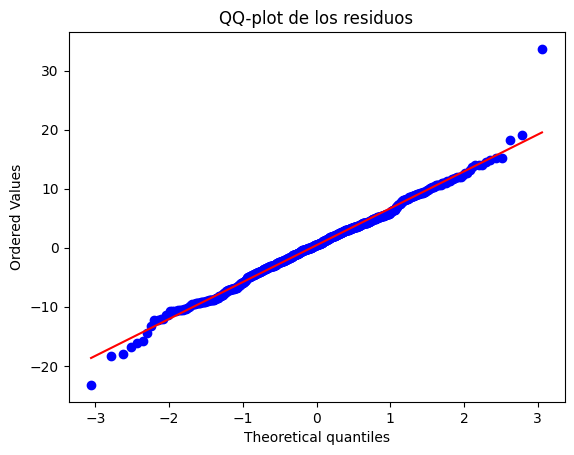

In [58]:

residuos = y_val_split - y_pred_A

print("Normalidad de los residuos:")
stat, p_valor = shapiro(residuos)
print(f"Estadístico: {stat:.4f}, p-valor: {p_valor:.6f}")
print("¿Se distribuyen normal?", "Sí" if p_valor > 0.05 else "No")

# QQ-plot
import matplotlib.pyplot as plt
probplot(residuos, dist="norm", plot=plt)
plt.title("QQ-plot de los residuos")
plt.show()

#### Interpretación de la normalidad (Shapiro-Wilk)

p-value ≈ 0.0003: se rechaza la normalidad de los residuos. El QQ-plot lo confirma visualmente: los puntos siguen bien la línea de referencia en el centro, pero se desvían en las colas.

El incumplimiento de la normalidad no afecta la insesgadez de los coeficientes de mínimos cuadrados ni la capacidad predictiva general del modelo. por lo tanto, el modelo sigue siendo útil para predecir y para comparar la magnitud relativa de los coeficientes, pero las afirmaciones deben tomarse con cautela.

### 5.2.2 Verificación del Supuesto de Homocedasticidad

Homocedasticidad (Breusch-Pagan)
Estadístico LM: 39.0984, p-valor: 0.251489
¿Varianza constante (homocedástico)? Sí


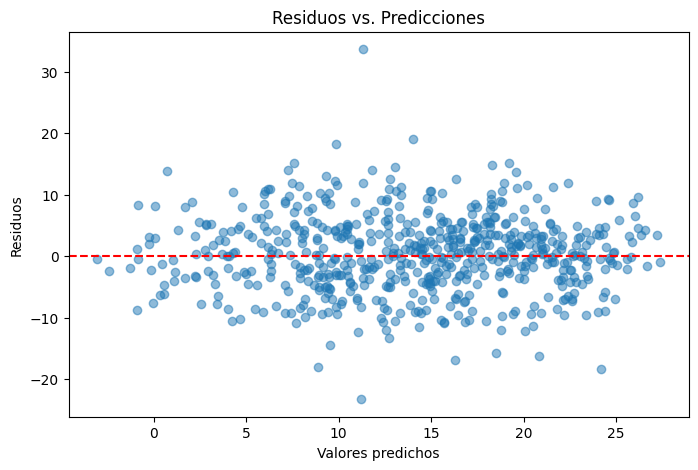

In [59]:
X_val_transformado = pipeline_A.named_steps['preprocessor'].transform(X_val_split)
X_val_con_constante = sm.add_constant(X_val_transformado)

print("Homocedasticidad (Breusch-Pagan)")
bp_stat, bp_pvalue, _, _ = het_breuschpagan(residuos, X_val_con_constante)
print(f"Estadístico LM: {bp_stat:.4f}, p-valor: {bp_pvalue:.6f}")
print("¿Varianza constante (homocedástico)?", "Sí" if bp_pvalue > 0.05 else "No")

# Gráfico de residuos vs predicciones (para visualizar el patrón)
plt.figure(figsize=(8,5))
plt.scatter(y_pred_A, residuos, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs. Predicciones")
plt.show()

#### Interpretación de Homocedasticidad
El test de Breusch-Pagan arrojó un estadístico LM ≈ 39 con un p-valor mayor al umbral de significancia de 0.05. Esto indica que no hay evidencia suficiente para rechazar el supuesto de homocedasticidad: la varianza de los residuos se mantiene razonablemente constante a lo largo de todo el rango de valores predichos. Esto se confirma visualmente en el gráfico de residuos vs. predicciones, donde la dispersión de los puntos es pareja.

### 5.2.3 Verificación del Supuesto de Independencia (Durbin-Watson)

In [60]:
print("3. Independencia de los residuos (Durbin-Watson)")
dw_stat = durbin_watson(residuos)
print(f"Estadístico Durbin-Watson: {dw_stat:.4f}")

3. Independencia de los residuos (Durbin-Watson)
Estadístico Durbin-Watson: 1.8732


#### Interpretación de los Residuos
El estadístico de Durbin-Watson obtenido fue 1.87, un valor muy cercano a 2, lo que indica ausencia de autocorrelación relevante entre los residuos consecutivos. El hecho de que el estadístico se mantenga dentro del rango aceptable sugiere que las variables meteorológicas del día actual capturan adecuadamente esa dependencia temporal.

### 5.2.4 Verificación del Supuesto de Multicolinealidad (VIF)

In [61]:
print("4. Multicolinealidad (VIF)")

# Convertir la matriz transformada a DataFrame con nombres de columnas
X_val_df = pd.DataFrame(X_val_transformado, columns=nombres_completos)

vif_data = pd.DataFrame()
vif_data['Variable'] = X_val_df.columns
vif_data['VIF'] = [variance_inflation_factor(X_val_df.values, i) for i in range(X_val_df.shape[1])]

vif_data = vif_data.sort_values('VIF', ascending=False)
display(vif_data)

4. Multicolinealidad (VIF)


,Variable,VIF
34,sector_viento_SO,24.236533
1,presion_min,21.330425
0,presion_media,19.387660
2,presion_max,16.263183
31,sector_viento_O,15.403750
32,sector_viento_S,14.691694
29,sector_viento_NE,10.090246
24,direccion_viento_cos,10.011964
5,humedad_min,9.666684
23,direccion_viento_sin,9.288659


#### Interpretación de la multicolinealidad (VIF)

Usando el criterio habitual (VIF > 10 indica multicolinealidad severa y 5–10 moderada), el análisis muestra tres focos claros de redundancia:

1. registros_del_dia: su VIF resulta extremo porque la variable es casi constante. Una variable prácticamente sin varianza no aporta información y desestabiliza el cálculo.
2. El bloque de presión (presion_min = 21, presion_media = 19, presion_max = 16): las tres versiones de la presión están fuertemente correlacionadas entre sí; el mínimo, la media y el máximo diarios de una variable física lenta como la presión se mueven juntos.
3. **Dirección del viento: sector_viento y la codificación cíclica codifican la misma información física, por lo que tener ambas duplica la señal.

Estos hallazgos motivan la desicion de eliminar la variable casi constante, conservar una sola versión de la presión y una sola representación de la dirección del viento.

In [62]:
print(data['registros_del_dia'].describe())
print(data['registros_del_dia'].value_counts().head(10))

count    2396.000000
mean      143.958264
std         1.385856
min        90.000000
25%       144.000000
50%       144.000000
75%       144.000000
max       144.000000
Name: registros_del_dia, dtype: float64
registros_del_dia
144.0    2390
143.0       3
142.0       1
103.0       1
90.0        1
Name: count, dtype: int64


## 5.3 Depuración del Modelo Final

El análisis del VIF mostró tres fuentes de multicolinealidad que llevan a ajustar el conjunto de variables predictoras:

1. registros_del_dia se elimina del modelo, dado que alrededor del 97 % de las observaciones tienen el valor máximo y la variable tiene varianza casi nula.
2. De las variables de presión se conserva únicamente presion_media y se eliminan presion_min y presion_max
3. En la representación de la dirección del viento se conserva la codificación cíclica y se elimina sector_viento, cuyas dummies alcanzaban VIF de hasta 24.

Tras estos ajustes, se vuelve a entrenar el modelo y se recalculan las métricas de desempeño y el VIF.

### 5.3.1 Redefinición de Columnas y Reentrenamiento Final

In [63]:
# Columnas numéricas finales para el modelo ajustado (Estrategia A depurada)
num_cols_final = [
    'presion_media',  # se quitan presion_min y presion_max
    'presion_desv',
    'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
    'viento_media', 'viento_min', 'viento_max', 'viento_desv',
    'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
    'viento_norte', 'viento_este',
    'anio', 'dia_del_anio',
    # se quita registros_del_dia
    'mes_sin', 'mes_cos', 'direccion_viento_sin', 'direccion_viento_cos'
]

# Columnas categóricas finales (se quita sector_viento)
cat_cols_final = ['estacion_anio']

print("Total de predictoras finales:", len(num_cols_final) + len(cat_cols_final))

Total de predictoras finales: 23


### Reconstrucción del preprocesador

Se reconstruye el ColumnTransformer con las columnas depuradas.

In [64]:
num_transformer_final = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer_final = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor_final = ColumnTransformer(transformers=[
    ('num', num_transformer_final, num_cols_final),
    ('cat', cat_transformer_final, cat_cols_final)
])

pipeline_final = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('model', LinearRegression())
])

### Reconstrucción de las matrices y reentrenamiento

Se seleccionan las columnas finales sobre los conjuntos ya divididos, manteniendo exactamente el mismo split 75/25 con semilla 42 para que las métricas sean comparables con las de la sección 5.1, y se reentrena el pipeline depurado.

In [65]:
columnas_finales = num_cols_final + cat_cols_final

X_train_final = X_train[columnas_finales]
X_train_split_final = X_train_split[columnas_finales]
X_val_split_final = X_val_split[columnas_finales]

pipeline_final.fit(X_train_split_final, y_train_split)
print("Pipeline final entrenado.")

Pipeline final entrenado.


### Métricas del modelo depurado

Se recalculan RMSE, MAE y R² sobre el mismo conjunto de validación, para medir el costo (o beneficio) de haber eliminado las variables redundantes.

In [66]:
y_pred_final = pipeline_final.predict(X_val_split_final)

rmse_final = np.sqrt(mean_squared_error(y_val_split, y_pred_final))
mae_final = mean_absolute_error(y_val_split, y_pred_final)
r2_final = r2_score(y_val_split, y_pred_final)

print(f"RMSE: {rmse_final:.4f}")
print(f"MAE: {mae_final:.4f}")
print(f"R2: {r2_final:.4f}")

print("\nComparación con la Estrategia A original")
print(f"A original -> RMSE: {rmse_A:.4f}, MAE: {mae_A:.4f}, R2: {r2_A:.4f}")
print(f"A depurada -> RMSE: {rmse_final:.4f}, MAE: {mae_final:.4f}, R2: {r2_final:.4f}")

RMSE: 6.2759
MAE: 4.8803
R2: 0.5184

Comparación con la Estrategia A original
A original -> RMSE: 6.2745, MAE: 4.8867, R2: 0.5186
A depurada -> RMSE: 6.2759, MAE: 4.8803, R2: 0.5184


### Verificación del VIF tras la depuración

Se recalcula el VIF sobre la matriz transformada final para confirmar que la multicolinealidad severa quedó resuelta.

In [67]:
nombres_num_final = num_cols_final
nombres_cat_final = pipeline_final.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols_final)
nombres_completos_final = list(nombres_num_final) + list(nombres_cat_final)

X_val_transformado_final = pipeline_final.named_steps['preprocessor'].transform(X_val_split_final)
X_val_df_final = pd.DataFrame(X_val_transformado_final, columns=nombres_completos_final)

vif_final = pd.DataFrame()
vif_final['Variable'] = X_val_df_final.columns
vif_final['VIF'] = [variance_inflation_factor(X_val_df_final.values, i) for i in range(X_val_df_final.shape[1])]

display(vif_final.sort_values('VIF', ascending=False))

,Variable,VIF
3,humedad_min,9.609584
5,humedad_desv,7.705459
15,viento_este,5.921557
6,viento_media,5.471711
14,viento_norte,5.392504
10,rafaga_media,4.030898
8,viento_max,3.938784
20,direccion_viento_sin,3.908354
21,direccion_viento_cos,3.362376
13,rafaga_desv,2.845556


### 5.3.2 Resultado tras la depuración por multicolinealidad

Tras eliminar las variables redundantes el VIF máximo bajó, y ya no hay multicolinealidad severa. La correlación que persiste dentro del grupo de humedad es esperable físicamente y no impide interpretar el modelo.

Las métricas de desempeño se mantuvieron prácticamente sin cambios, lo que confirma que las variables eliminadas no aportaban información predictiva adicional relevante. 

### 5.3.3 Revalidación de supuestos sobre el modelo depurado

Los supuestos de la sección 5.2 se verificaron sobre la Estrategia A completa. Como el modelo que finalmente se interpreta y se usa para predecir es el depurado, se repiten las tres pruebas (normalidad, homocedasticidad e independencia) sobre sus residuos de validación.

Shapiro-Wilk: estadístico=0.9880, p-valor=0.000057 -> residuos NO normales
Breusch-Pagan: LM=30.3575, p-valor=0.211180 -> homocedástico
Durbin-Watson: 1.8763 (cercano a 2 = independencia)


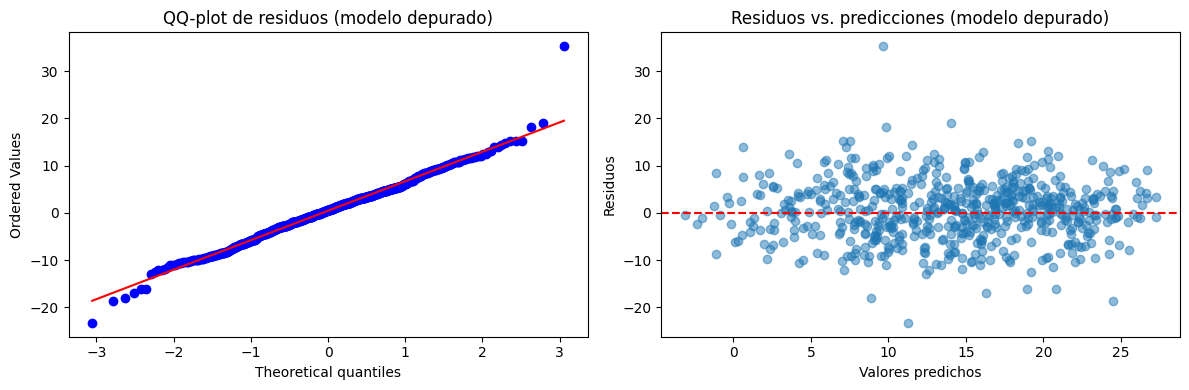

In [68]:
residuos_final = y_val_split - y_pred_final

# 1. Normalidad (Shapiro-Wilk)
stat_f, p_f = shapiro(residuos_final)
print(f"Shapiro-Wilk: estadístico={stat_f:.4f}, p-valor={p_f:.6f} -> "
      f"{'residuos normales' if p_f > 0.05 else 'residuos NO normales'}")

# 2. Homocedasticidad (Breusch-Pagan)
X_val_const_final = sm.add_constant(X_val_transformado_final)
bp_stat_f, bp_p_f, _, _ = het_breuschpagan(residuos_final, X_val_const_final)
print(f"Breusch-Pagan: LM={bp_stat_f:.4f}, p-valor={bp_p_f:.6f} -> "
      f"{'homocedástico' if bp_p_f > 0.05 else 'heterocedástico'}")

# 3. Independencia (Durbin-Watson)
print(f"Durbin-Watson: {durbin_watson(residuos_final):.4f} (cercano a 2 = independencia)")

# Gráficos de apoyo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
probplot(residuos_final, dist="norm", plot=axes[0])
axes[0].set_title("QQ-plot de residuos (modelo depurado)")
axes[1].scatter(y_pred_final, residuos_final, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel("Valores predichos")
axes[1].set_ylabel("Residuos")
axes[1].set_title("Residuos vs. predicciones (modelo depurado)")
plt.tight_layout()
plt.show()

Las conclusiones se mantienen respecto al modelo sin depurar: los residuos no son normales, la varianza es constante y no hay autocorrelación relevante. Es decir, la depuración no alteró el comportamiento de los residuos.

## 5.4 Interpretación de Coeficientes del Modelo Final

In [69]:
# Extraer coeficientes del modelo final
coeficientes_final = pipeline_final.named_steps['model'].coef_
intercepto_final = pipeline_final.named_steps['model'].intercept_

tabla_coef_final = pd.DataFrame({
    'Variable': nombres_completos_final,
    'Coeficiente': coeficientes_final
}).sort_values('Coeficiente', key=abs, ascending=False)

print(f"Intercepto: {intercepto_final:.4f}")
display(tabla_coef_final)

# Confirmar cuál categoría de estacion_anio quedó como referencia (la que no aparece explícita)
print("Categorías de estacion_anio en el modelo:", nombres_cat_final)
print("Categoría de referencia (implícita):", [c for c in ['invierno','otono','primavera','verano'] if f'estacion_anio_{c}' not in nombres_cat_final])

Intercepto: 13.8104


,Variable,Coeficiente
14,viento_norte,-6.492195
13,rafaga_desv,-6.390919
5,humedad_desv,2.785574
19,mes_cos,-1.750378
3,humedad_min,-1.735918
17,dia_del_anio,1.705788
1,presion_desv,-1.352240
23,estacion_anio_primavera,-1.078230
18,mes_sin,-0.797908
16,anio,0.772307


Categorías de estacion_anio en el modelo: ['estacion_anio_otono' 'estacion_anio_primavera' 'estacion_anio_verano']
Categoría de referencia (implícita): ['invierno']


### 5.4.1 Tabla de importancia de variables

Como todas las variables numéricas fueron estandarizadas (media 0, desviación 1) antes de entrar a la regresión, la magnitud absoluta de cada coeficiente es directamente comparable entre variables: representa el cambio esperado (en °C) de la temperatura máxima del día siguiente ante un aumento de una desviación estándar de esa variable, manteniendo las demás constantes. Por eso |coeficiente| funciona como medida de **importancia** de cada variable; se agrega también la importancia relativa normalizada (porcentaje del total).

Tabla de importancia de variables (modelo final):


,Variable,Coeficiente,|Coeficiente|,Importancia relativa (%)
0,viento_norte,-6.492195,6.492195,20.68
1,rafaga_desv,-6.390919,6.390919,20.36
2,humedad_desv,2.785574,2.785574,8.87
3,mes_cos,-1.750378,1.750378,5.58
4,humedad_min,-1.735918,1.735918,5.53
5,dia_del_anio,1.705788,1.705788,5.43
6,presion_desv,-1.352240,1.352240,4.31
7,estacion_anio_primavera,-1.078230,1.078230,3.43
8,mes_sin,-0.797908,0.797908,2.54
9,anio,0.772307,0.772307,2.46


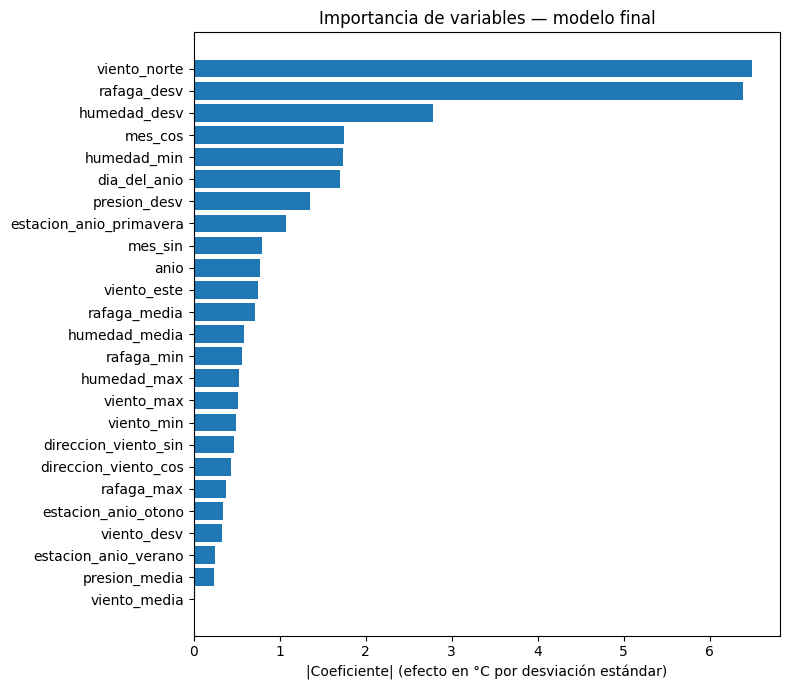

In [70]:
tabla_importancia = tabla_coef_final.copy()
tabla_importancia['|Coeficiente|'] = tabla_importancia['Coeficiente'].abs()
tabla_importancia['Importancia relativa (%)'] = (
    100 * tabla_importancia['|Coeficiente|'] / tabla_importancia['|Coeficiente|'].sum()
).round(2)
tabla_importancia = tabla_importancia.sort_values('|Coeficiente|', ascending=False).reset_index(drop=True)

print("Tabla de importancia de variables (modelo final):")
display(tabla_importancia)

# Visualización de la importancia
plt.figure(figsize=(8, 7))
plt.barh(tabla_importancia['Variable'][::-1], tabla_importancia['|Coeficiente|'][::-1])
plt.xlabel('|Coeficiente| (efecto en °C por desviación estándar)')
plt.title('Importancia de variables — modelo final')
plt.tight_layout()
plt.show()

### 5.4.2 Variables con mayor influencia


1. viento_norte: a mayor componente norte del viento, menor la temperatura máxima del día siguiente
2. rafaga_desv: mayor variabilidad de las ráfagas durante el día se asocia con menor temperatura al día siguiente.
3. humedad_desv y humedad_min: días con humedad mínima baja van antes de días calurosos.



El hallazgo más interesante es que las medias importan poco, ya que las variables de mediass estan entre los coefencientes mas minimos.

# 6. Predicción en Conjunto de Test y Exportación del archivo CSV

## 6.1 Reentrenamiento con 100% de Datos de Train

Hasta este punto, pipeline_final está entrenado solo con el 75 % de los datos. Para generar las predicciones definitivas sobre el archivo de test conviene reentrenar el modelo con todas las filas limpias de entrenamiento.

In [71]:
pipeline_final.fit(X_train_final, y_train)

print(f"Pipeline final reentrenado con el 100% del train: {X_train_final.shape[0]} filas")


Pipeline final reentrenado con el 100% del train: 2474 filas


## 6.2 Preparación del Archivo de Test y Generación de Resultados

In [72]:
X_test_final = X_test[columnas_finales]

print("X_test_final shape:", X_test_final.shape)
print("Nulos en X_test_final:")
print(X_test_final.isnull().sum())

X_test_final shape: (364, 23)
Nulos en X_test_final:
presion_media           0
presion_desv            0
humedad_media           0
humedad_min             0
humedad_max             0
humedad_desv            0
viento_media            0
viento_min              0
viento_max              0
viento_desv             0
rafaga_media            0
rafaga_min              0
rafaga_max              0
rafaga_desv             0
viento_norte            0
viento_este             0
anio                    0
dia_del_anio            0
mes_sin                 0
mes_cos                 0
direccion_viento_sin    0
direccion_viento_cos    0
estacion_anio           0
dtype: int64


## 6.3 Generar las predicciones

In [73]:
predicciones_test = pipeline_final.predict(X_test_final)

print("Predicciones generadas:", len(predicciones_test))
print("Rango de predicciones:", predicciones_test.min(), "a", predicciones_test.max())

# Comparar el rango con lo que sabemos de train, como chequeo de sensatez
print("\nRango de temp_max_manana en train:", y_train.min(), "a", y_train.max())

Predicciones generadas: 364
Rango de predicciones: -1.8433188030206846 a 30.818782016680665

Rango de temp_max_manana en train: -15.23 a 44.978


## 6.4 Construcción y Descarga del CSV Final

In [74]:
# Partimos del archivo de test crudo con las columnas originales
resultado_test = datos_test_crudo.copy()

# Agregamos la columna de predicciones
resultado_test['temp_max_manana'] = predicciones_test

# Verificación antes de exportar
print("Shape del archivo final:", resultado_test.shape)
display(resultado_test.head())

# Exportar a CSV con el nombre exigido por la rúbrica
# (en Colab se descarga desde el panel de archivos de la izquierda)
resultado_test.to_csv('Datos Test Lab 1.csv', index=False)
print("\nArchivo exportado correctamente.")

Shape del archivo final: (364, 27)


,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,viento_min,viento_max,viento_desv,rafaga_media,rafaga_min,rafaga_max,rafaga_desv,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
0,01.01.2016,998.9860,995.57,1000.60,1.1082,96.1493,90.8,98.7,2.0034,0.9649,0.18,3.13,0.5552,1.7068,0.40,5.17,0.8415,-0.8328,0.0927,173.6501,144,2016,1,invierno,January,S,1.623026
1,02.01.2016,991.4241,989.27,995.51,1.9413,92.3236,85.8,96.8,2.6562,1.9886,0.21,4.01,1.0960,2.8128,0.52,5.37,1.3604,1.1161,0.6688,30.9301,144,2016,2,invierno,January,NE,2.058385
2,03.01.2016,984.0232,974.12,989.39,4.5841,83.6056,73.9,94.7,6.9967,2.4992,0.60,4.46,0.8034,3.9316,1.28,6.49,1.2558,-0.7923,1.2638,122.0847,144,2016,3,invierno,January,SE,1.379012
3,04.01.2016,968.2449,966.52,974.02,1.9034,85.4688,75.5,93.8,5.8148,2.0932,0.25,4.06,0.8433,3.4434,0.48,6.25,1.4544,-1.6217,0.7020,156.5944,144,2016,4,invierno,January,SE,5.192485
4,05.01.2016,970.0099,967.85,972.90,1.6668,94.3521,92.0,96.8,1.4253,1.8380,0.45,3.21,0.6245,2.4610,0.80,4.41,0.7284,1.6549,0.7109,23.2458,144,2016,5,invierno,January,NE,1.163416



Archivo exportado correctamente.


# 7. Análisis de resultados

## **7.1 ¿Cuál fue el valor de los diferentes coeficientes obtenidos en el mejor modelo?**
El modelo final de la Estrategia A obtuvo un intercepto de 13.81, que corresponde a la predicción cuando todas las variables estandarizadas están en su promedio y la estación es invierno. Las variables con mayor peso en la predicción fueron viento_norte, rafaga_desv, humedad_desv, mes_cos, humedad_min y dia_del_anio. Las demás variables obtuvieron coeficientes menores, entre 0.0 y 1.35 en valor absoluto.

## **7.2 ¿Cuál modelo ofrece el mejor rendimiento sobre el conjunto test? ¿Qué interpretación puedes darles a los valores obtenidos sobre las métricas de rendimiento?**
Como el archivo de test del laboratorio no está etiquetado, la comparación se hace sobre un conjunto de validación (25 %) que los modelos no vieron durante el entrenamiento. La Estrategia A  superó a la Estrategia B en las tres métricas:

RMSE: 6.27 °C frente a 6.49 °C.

MAE: 4.89 °C frente a 5.08 °C.

R²: 0.519 frente a 0.485.

Luego se eliminaron de la Estrategia A las variables con alta multicolinealidad. Al recalcular las métricas, los resultados fueron prácticamente iguales, lo que indica que las variables eliminadas no aportaban información relevante y que el modelo depurado es preferible por ser más simple e interpretable.

En cuanto a la interpretación de las métricas: el RMSE de 6.3 indica que las predicciones se alejan de la temperatura real en ese orden de magnitud, dando mayor peso a los errores grandes. El MAE de 4.9 muestra que el error absoluto típico es menor Finalmente,el R² de 0.52 significa que el modelo explica aproximadamente la mitad de la variabilidad de la temperatura máxima del día siguiente.

## **7.3 ¿Cuáles variables fueron seleccionadas con el modelo seleccionado? A partir de estas, ¿qué interpretación de cara al problema puedes dar?**
El modelo final utiliza 25 variables predictoras. Se eliminaron presion_min, presion_max, registros_del_dia y sector_viento porque tenían una relación demasiado alta con otras variables ya incluidas.


Para AlpesPlanck, estos resultados indican que conviene monitorear no solo los promedios diarios sino la estabilidad de las condiciones  y la componente norte del viento. Ese conocimiento puede alimentar sistemas de alerta temprana y ayudar a priorizar qué sensores y agregaciones vale la pena mantener con mejor calidad de datos.

## **7.4 ¿Cómo representar la regresión lineal de forma matemática? Indique el método utilizado y el proceso para resolverlo**


El método matemático que utilizamos fue el descenso del gradiente, que es el enfoque que vimos en clase. La idea principal es comenzar con unos pesos iniciales y ajustar esos valores de forma iterativa para reducir el error del modelo. En cada paso se calcula cuánto se está equivocando la predicción, se observa la dirección en la que deben moverse los parámetros y se actualiza el valor de cada coeficiente. Este proceso se repite varias veces hasta que el error deja de disminuir de manera significativa y el modelo queda estable.

Este enfoque funciona bien en regresión lineal porque la función de error es cuadrática, por lo que tiene una forma regular y se puede optimizar de manera continua. El gradiente indica la pendiente del error respecto a cada peso, y eso nos dice hacia dónde moverlos para mejorar la predicción. De esta forma, el modelo aprende poco a poco y encuentra los coeficientes que mejor se ajustan a los datos.

En términos matemáticos, el modelo se puede escribir como:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p + \varepsilon$$

Donde $y$ es la variable objetivo, $x_1, x_2, \dots, x_p$ son las variables predictoras, $\beta_0$ es el intercepto y los $\beta_i$ son los coeficientes que se van ajustando. El descenso del gradiente realiza este ajuste de forma iterativa para encontrar los valores que minimizan el error del modelo.

En resumen, el proceso consistió en preparar los datos, estandarizarlos, ajustar el modelo con descenso del gradiente y evaluar su desempeño con validación. Esto nos permitió aprender cómo cada variable influye en la predicción y entender mejor la relación entre los datos y la variable objetivo.

## **7.5 ¿Qué tipos de sesgo podría afectar los resultados y por qué? Describe dos tipos de sesgo**

1. Sesgo de selección (muestreo). Todos los datos provienen de una única estación meteorológica y de una ventana temporal limitada. La muestra no representa otros climas, altitudes ni microclimas: el modelo aprendió los patrones específicos de un clima especifico. Si AlpesPlanck usara este modelo en otra región sus predicciones estarían sistemáticamente sesgadas. Este sesgo afecta directamente el objetivo del negocio porque esos eventos son justamente los casos "fuera de lo típico" del histórico con el que se entrenó.

2. Sesgo de medición. Los propios datos demostraron que los sensores y el proceso de registro introducen errores sistemáticos: valores centinela −9999 en viento y ráfagas, presiones registradas 10 veces por encima de su valor real y mínimos y máximos intercambiados en cientos de filas. Cuando estos errores no se corrigen, los coeficientes se estiman sobre datos distorsionados y el modelo aprende relaciones falsas o atenuadas. 


# 8. Uso de herramientas de IA generativa

## 8.1 Declaración del uso

Durante el desarrollo del laboratorio se utilizaron Claude (Anthropic) y Gemini (Google) como herramientas de apoyo para resolver dudas conceptuales, revisar aspectos de implementación y complementar el análisis del notebook. Se usaron como apoyo al proceso de aprendizaje y no como sustituto del razonamiento ni de las decisiones técnicas tomadas por el grupo.

Los principales usos fueron:

- Consultar sobre la organización jerárquica del notebook con Markdown (títulos, subtítulos y secciones).
- Investigar cómo representar `mes` y `direccion_viento` como variables cíclicas con seno y coseno, dado que sus valores tienen naturaleza circular: diciembre y enero son meses consecutivos aunque estén en extremos numéricos, igual que los ángulos cercanos a 0° y 360°.
- Apoyar el agrupamiento de los valores errados de `estacion_anio`, `mes` y `sector_viento` en sus categorías correctas definitivas con los diccionarios de la sección 3.3.
- Plantear las ideas iniciales de las dos estrategias de preparación que después se compararon.
- Revisar la función `limpiar_datos_clima` para comprobar que las transformaciones aplicadas a train también se apliquen de manera consistente a test.
- Consultar métricas y supuestos adicionales para comparar los modelos en la validación: multicolinealidad, independencia y normalidad de los residuos.
- Investigar tipos de sesgo como apoyo para las preguntas de análisis.
- Hacer una revisión final del notebook contra la rúbrica, de donde salió la corrección de las escalas mezcladas de humedad (sección 3.6.2).

## 8.2 Prompts utilizados (resumidos)

- Cómo organizar jerárquicamente un notebook mediante Markdown.
- Cómo transformar variables como meses y grados para representar correctamente su naturaleza cíclica.
- Cómo unificar en pandas categorías escritas en varios idiomas y con errores de digitación.
- Cómo verificar que una función de limpieza aplique al conjunto test las mismas transformaciones realizadas sobre train.
- Qué métricas y supuestos estadísticos adicionales pueden usarse para evaluar y comparar modelos (multicolinealidad, independencia, normalidad).
- Cuáles son los principales tipos de sesgo que pueden presentarse en un análisis de datos.
- Revisar el notebook contra la rúbrica del laboratorio y decir qué falta o está flojo.

## 8.3 Análisis crítico del resultado

Las respuestas de la IA se usaron como punto de partida y luego se contrastaron con los conceptos del curso y con el comportamiento real de los datos y modelos del laboratorio.

**¿Qué fue correcto y útil?** La explicación sobre variables cíclicas sirvió para entender que no siempre es adecuado representar una variable circular con su valor numérico directo; la idea se adaptó al contexto del laboratorio y se verificó antes de incorporarla al procesamiento. También fue útil la orientación sobre supuestos y métricas de validación, la revisión de consistencia train/test de `limpiar_datos_clima` y los diccionarios de categorías, que coinciden con lo visto en las prácticas del curso.

**¿Qué errores o limitaciones se identificaron?** La IA no detectó al inicio el problema más grande de los datos: la humedad con dos escalas mezcladas, pues la validación de rangos propuesta solo miraba valores fuera de 0 a 100 y un valor como 0.9 pasaba sin alerta. Además, las métricas y supuestos sugeridos no se incorporaron automáticamente: se evaluó cuáles eran pertinentes para el problema y cuáles aportaban información real.

**¿Qué decisiones técnicas se modificaron?** La corrección de escala de humedad se limitó a `humedad_media` y `humedad_min`, porque `humedad_desv` tiene valores pequeños legítimos y no valía la pena el riesgo de dañar datos buenos; la mejora se validó comparando el RMSE con el mismo split antes de aceptarla. La implementación final de `limpiar_datos_clima` se revisó y ajustó según el flujo de procesamiento del notebook.

**¿Qué conceptos del curso permitieron evaluar las respuestas?** Los supuestos de la regresión lineal, el VIF, la división train/validación con semilla fija para comparaciones justas y la lectura de coeficientes estandarizados como medida de importancia.

## 8.4 Aportes propios

- La exploración inicial y las decisiones de qué corregir, intercambiar o anular en la limpieza.
- La selección del modelo final y la depuración por multicolinealidad.
- La interpretación de los resultados para el caso AlpesPlanck.
- La adaptación y verificación de cada sugerencia de la IA antes de incorporarla: entendemos y podemos explicar todo el contenido entregado.